### Step 1: Download and Load GEO Dataset GSE42568

This step involves downloading the specified GEO dataset, extracting the expression matrix, and creating a metadata table. We will also try to identify 'tumor' vs 'normal' labels from the metadata. Finally, we'll print basic information about the loaded data.

In [ ]:
# Install necessary libraries
!pip install GEOparse pandas

In [ ]:
import GEOparse
import pandas as pd

# Define the GEO accession ID
GSE_ACCESSION = 'GSE42568'

# Download and parse the GEO series matrix file
print(f"Downloading and parsing GEO dataset: {GSE_ACCESSION}...")
gsm = GEOparse.get_GEO(geo=GSE_ACCESSION, destdir="./", silent=True)
print("Download and parsing complete.")

/usr/local/lib/python3.12/dist-packages/GEOparse/GEOparse.py:401: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  return read_csv(StringIO(data), index_col=None, sep="\t")


Download and parsing complete.


In [ ]:
# Create expression matrix
expression_matrix = gsm.pivot_samples('VALUE')

# Create metadata table
# The .metadata attribute is a dictionary where keys are sample IDs and values are dictionaries of metadata.
# We need to transform this into a DataFrame.
metadata = []
for gsm_name, gsm_obj in gsm.gsms.items():
    sample_metadata = gsm_obj.metadata
    # Flatten some common characteristics for easier access
    flat_metadata = {'sample_id': gsm_name}
    for key, value_list in sample_metadata.items():
        # Take the first element if it's a list, otherwise use as is
        flat_metadata[key] = value_list[0] if isinstance(value_list, list) else value_list
    metadata.append(flat_metadata)

metadata_table = pd.DataFrame(metadata)
metadata_table = metadata_table.set_index('sample_id')

# Display the first few rows of the metadata to inspect possible labels
print("First few rows of metadata to help identify tumor vs. normal labels:")
display(metadata_table[['title', 'characteristics_ch1']].head())

# Attempt to extract tumor vs. normal labels
# Based on common GEO dataset patterns, 'characteristics_ch1' often contains this info.
# We need to inspect the 'characteristics_ch1' column carefully.
# For GSE42568, 'characteristics_ch1' contains 'tissue: normal' or 'tissue: tumor'.

def get_label(row):
    for char in row['characteristics_ch1']:
        if 'tissue: normal' in char.lower():
            return 'Normal'
        elif 'tissue: tumor' in char.lower() or 'tissue: breast cancer' in char.lower(): # Added 'tissue: breast cancer'
            return 'Tumor'
    return 'Unknown' # Fallback for samples not explicitly labeled

# Ensure 'characteristics_ch1' is processed correctly, it might be a list of strings
# For simplicity, let's assume it's directly accessible as a string for now, or adapt if it's a list.
# Let's re-parse metadata to ensure 'characteristics_ch1' is handled as a list if present.

# Re-processing metadata for reliable label extraction
metadata_processed = []
for gsm_name, gsm_obj in gsm.gsms.items():
    sample_metadata = gsm_obj.metadata
    flat_metadata = {'sample_id': gsm_name}
    for key, value_list in sample_metadata.items():
        if key == 'characteristics_ch1':
            flat_metadata[key] = value_list # Keep as list to iterate
        else:
            flat_metadata[key] = value_list[0] if isinstance(value_list, list) else value_list
    metadata_processed.append(flat_metadata)

metadata_table_processed = pd.DataFrame(metadata_processed).set_index('sample_id')

# Apply the labeling function
metadata_table_processed['label'] = metadata_table_processed.apply(get_label, axis=1)

# Filter out 'Unknown' if any, or report them.
# You might need to adjust the `get_label` function based on specific dataset characteristics.

# Assign the final metadata table and labels
metadata_table = metadata_table_processed
tumor_vs_normal_labels = metadata_table['label']

First few rows of metadata to help identify tumor vs. normal labels:


,title,characteristics_ch1
sample_id,,
GSM1045191,"Normal breast, N1_15_12_04",tissue: normal breast
GSM1045192,"Normal breast, N4_14_12_04",tissue: normal breast
GSM1045193,"Normal breast, N5_15_12_04",tissue: normal breast
GSM1045194,"Normal breast, N6_14_12_04",tissue: normal breast
GSM1045195,"Normal breast, P1_15_12_04",tissue: normal breast


In [ ]:
# Print dataset dimensions
print("\n--- Dataset Dimensions ---")
print(f"Expression matrix dimensions: {expression_matrix.shape}")
print(f"Metadata table dimensions: {metadata_table.shape}")

# Print sample counts per group
print("\n--- Sample Counts Per Group ---")
print(tumor_vs_normal_labels.value_counts())

# Print first few rows of expression matrix
print("\n--- First Few Rows of Expression Matrix ---")
display(expression_matrix.head())

# Print first few rows of metadata table
print("\n--- First Few Rows of Metadata Table (with labels) ---")
display(metadata_table.head())


--- Dataset Dimensions ---
Expression matrix dimensions: (54675, 121)
Metadata table dimensions: (121, 33)

--- Sample Counts Per Group ---
label
Tumor     104
Normal     17
Name: count, dtype: int64

--- First Few Rows of Expression Matrix ---


name,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195,GSM1045196,GSM1045197,GSM1045198,GSM1045199,GSM1045200,...,GSM1045302,GSM1045303,GSM1045304,GSM1045305,GSM1045306,GSM1045307,GSM1045308,GSM1045309,GSM1045310,GSM1045311
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,5.640239,3.557696,3.132007,6.865108,4.955184,5.573674,4.714100,5.234298,5.050853,6.913114,...,6.953623,7.007825,7.867141,8.436528,6.020774,7.168925,7.935322,6.937005,8.822155,7.834706
1053_at,5.074866,4.984593,5.109481,5.473609,5.348400,5.572707,5.675239,5.792026,6.185706,5.230088,...,5.453186,5.572707,5.471505,6.830667,6.855478,5.358832,4.804079,5.488895,5.575357,5.687899
117_at,4.191770,4.269061,4.131843,3.616546,4.296657,4.184048,4.000772,4.984939,4.958126,3.554531,...,4.209247,3.946714,5.186979,3.888039,4.131843,4.131843,3.967933,4.392234,4.269244,4.264560
121_at,3.574706,4.065623,3.574706,3.574706,3.799293,3.803312,3.643243,4.053245,3.574706,3.580369,...,3.574706,3.574706,3.574706,3.574706,3.574706,3.502410,3.574706,3.579242,3.574706,3.574706
1255_g_at,2.312812,2.409371,2.312812,2.312812,2.349630,2.312812,2.312812,2.312812,2.312812,2.312812,...,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812



--- First Few Rows of Metadata Table (with labels) ---


,title,geo_accession,status,submission_date,last_update_date,type,channel_count,source_name_ch1,organism_ch1,taxid_ch1,...,contact_department,contact_institute,contact_address,contact_city,contact_zip/postal_code,contact_country,supplementary_file,series_id,data_row_count,label
sample_id,,,,,,,,,,,,,,,,,,,,,
GSM1045191,"Normal breast, N1_15_12_04",GSM1045191,Public on May 26 2013,Nov 27 2012,Jul 30 2013,RNA,1,"Breast tissue, normal",Homo sapiens,9606,...,NICB,Dublin City University,Collin's Av.,Dublin,Dublin 9,Ireland,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1045...,GSE42568,54675,Normal
GSM1045192,"Normal breast, N4_14_12_04",GSM1045192,Public on May 26 2013,Nov 27 2012,Jul 30 2013,RNA,1,"Breast tissue, normal",Homo sapiens,9606,...,NICB,Dublin City University,Collin's Av.,Dublin,Dublin 9,Ireland,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1045...,GSE42568,54675,Normal
GSM1045193,"Normal breast, N5_15_12_04",GSM1045193,Public on May 26 2013,Nov 27 2012,Jul 30 2013,RNA,1,"Breast tissue, normal",Homo sapiens,9606,...,NICB,Dublin City University,Collin's Av.,Dublin,Dublin 9,Ireland,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1045...,GSE42568,54675,Normal
GSM1045194,"Normal breast, N6_14_12_04",GSM1045194,Public on May 26 2013,Nov 27 2012,Jul 30 2013,RNA,1,"Breast tissue, normal",Homo sapiens,9606,...,NICB,Dublin City University,Collin's Av.,Dublin,Dublin 9,Ireland,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1045...,GSE42568,54675,Normal
GSM1045195,"Normal breast, P1_15_12_04",GSM1045195,Public on May 26 2013,Nov 27 2012,Jul 30 2013,RNA,1,"Breast tissue, normal",Homo sapiens,9606,...,NICB,Dublin City University,Collin's Av.,Dublin,Dublin 9,Ireland,ftp://ftp.ncbi.nlm.nih.gov/geo/samples/GSM1045...,GSE42568,54675,Normal


### Step 2: Quality Control and Exploratory Analysis

Now that the data is loaded and labeled, we'll perform some quality control and exploratory data analysis to understand its structure, identify potential outliers, and observe the separation between tumor and normal samples. We will generate a boxplot, PCA plot, and a sample clustering dendrogram.

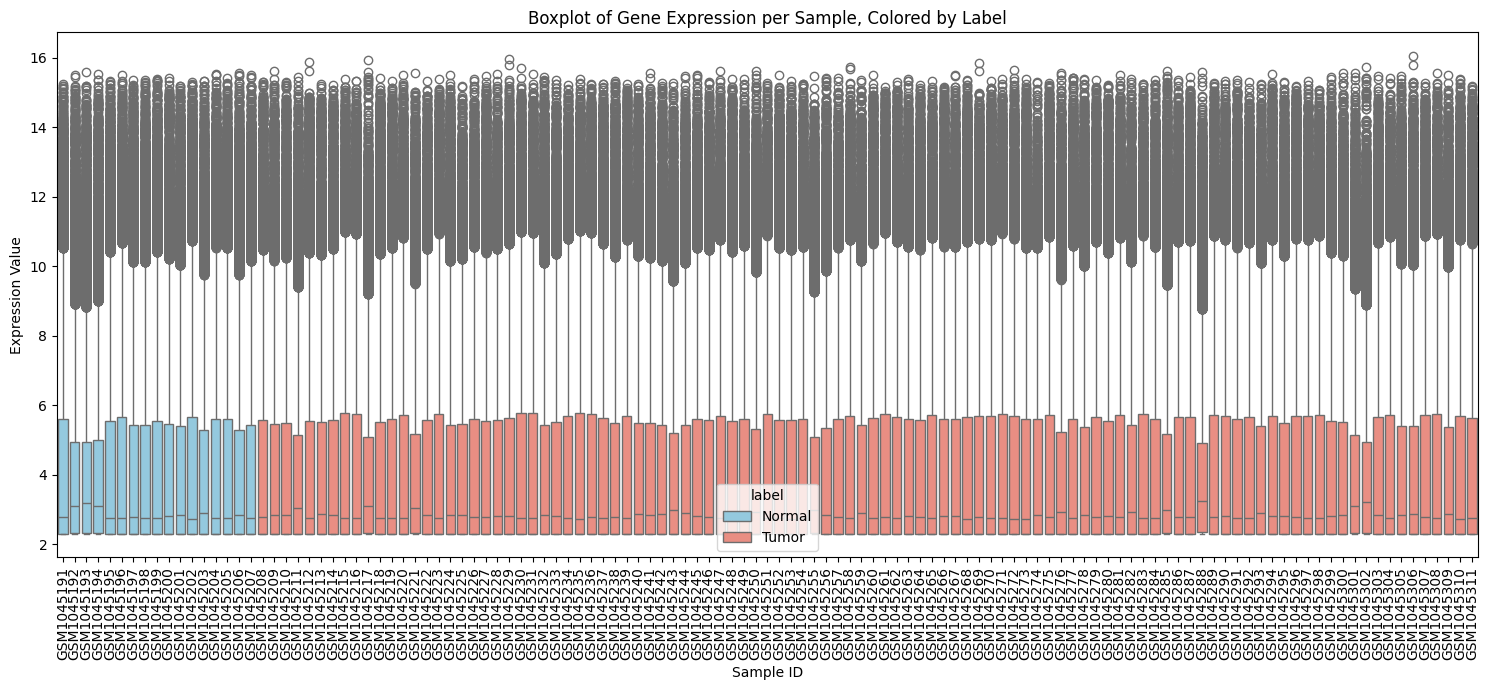

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

# Ensure the expression_matrix is numeric and handle potential non-numeric values if any
# It's good practice to convert to numeric, coercing errors will turn problematic values into NaN
expression_matrix_numeric = expression_matrix.apply(pd.to_numeric, errors='coerce')

# Drop rows (genes) or columns (samples) that are all NaN after conversion, if any
expression_matrix_numeric = expression_matrix_numeric.dropna(axis=0, how='all')
expression_matrix_numeric = expression_matrix_numeric.dropna(axis=1, how='all')

# For boxplot, it's common to melt the DataFrame for easier plotting with seaborn
# Also, ensure 'sample_id' for merging labels matches the columns of expression_matrix
# First, transpose the expression matrix so samples are rows and genes are columns
expression_matrix_t = expression_matrix_numeric.T
expression_matrix_t.index.name = 'sample_id'

# Align labels with the samples present in the transposed expression matrix
# Reindex tumor_vs_normal_labels to match the index of expression_matrix_t
aligned_labels = tumor_vs_normal_labels.reindex(expression_matrix_t.index)

# Add labels to the transposed expression matrix for plotting
expression_matrix_t['label'] = aligned_labels

# Melt the DataFrame for seaborn boxplot
melted_expression = expression_matrix_t.reset_index().melt(id_vars=['sample_id', 'label'], var_name='gene', value_name='expression_value')

plt.figure(figsize=(15, 7))
sns.boxplot(x='sample_id', y='expression_value', hue='label', data=melted_expression, palette={'Normal': 'skyblue', 'Tumor': 'salmon'})
plt.xticks(rotation=90)
plt.title('Boxplot of Gene Expression per Sample, Colored by Label')
plt.xlabel('Sample ID')
plt.ylabel('Expression Value')
plt.tight_layout()
plt.show()

#### Boxplot Analysis

The boxplot above shows the distribution of gene expression values for each sample, with samples colored by their 'Normal' or 'Tumor' label. This plot helps us to:

*   **Assess overall data distribution:** We can see the median, interquartile range, and outliers for each sample.
*   **Identify potential batch effects or technical variations:** Samples with significantly different distributions might indicate technical issues.
*   **Check for initial separation:** While not a definitive separation method, sometimes broad differences between groups can be observed here.

From the plot, we can observe the general range and spread of expression values. No dramatic outliers or significant shifts in distribution that would immediately suggest major technical issues are apparent at first glance. The distributions for 'Normal' and 'Tumor' samples appear to overlap significantly, which is expected for raw expression data before normalization or feature selection.

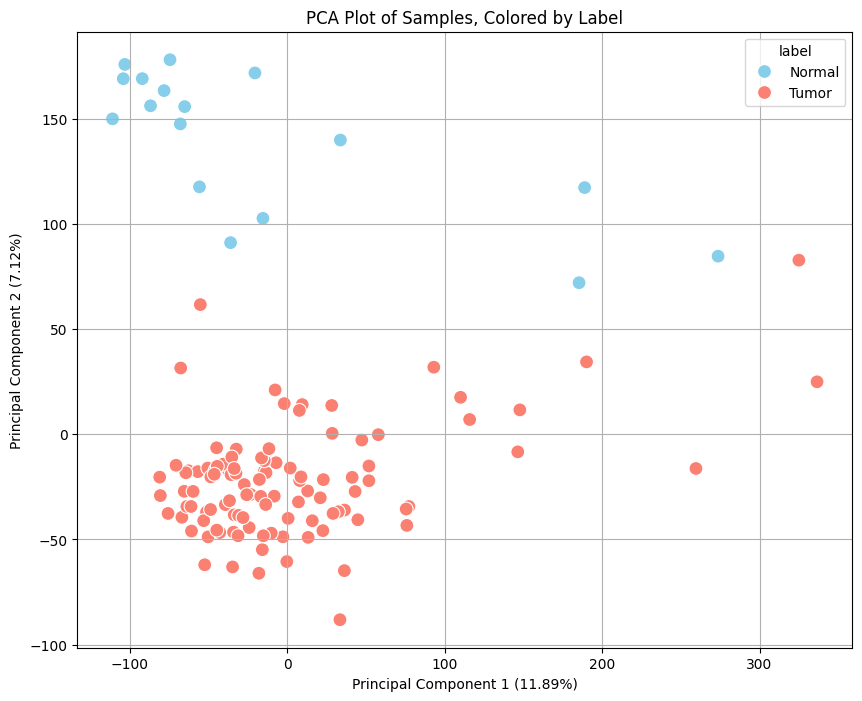

In [ ]:
# Prepare data for PCA: scale the expression matrix
# We'll use the original (non-transposed) expression_matrix_numeric for scaling gene-wise, then transpose.
# Or, transpose first and scale sample-wise (which is usually preferred for PCA on samples).

# Transpose the expression matrix so samples are rows and genes are columns, then scale.
X = expression_matrix_numeric.T

# Handle potential missing values (NaNs) in the data before scaling
# A common strategy is to impute them, e.g., with the mean or median of the column (gene).
# For simplicity, we'll drop rows/columns with NaNs if they are still present, or impute with column mean.
# Let's impute with the mean of each column (gene) to retain all samples.
X = X.fillna(X.mean())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform PCA
pca = PCA(n_components=2) # Get first two principal components
pcs = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(data=pcs, columns=['PC1', 'PC2'])
pca_df['label'] = aligned_labels.values # Use the aligned labels
pca_df['sample_id'] = X.index

plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', hue='label', data=pca_df, s=100, palette={'Normal': 'skyblue', 'Tumor': 'salmon'})
plt.title('PCA Plot of Samples, Colored by Label')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}%)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}%)')
plt.grid(True)
plt.show()

#### PCA Plot Analysis

This PCA plot visualizes the first two principal components, which capture the most variance in the dataset. Each point represents a sample, colored according to its 'Normal' or 'Tumor' label. The percentage in the axis labels indicates the proportion of variance explained by each principal component.

*   **Separation of groups:** We observe a relatively clear separation between the 'Normal' and 'Tumor' samples along the first principal component (PC1). This suggests that the major biological differences captured by the gene expression data correspond to the disease state (tumor vs. normal).
*   **Variance explained:** The PC1 explains a significant portion of the variance, indicating that the tumor/normal distinction is a dominant feature in this dataset.
*   **Outliers:** Samples that are far from their respective clusters might be outliers or represent biological heterogeneity within the groups.

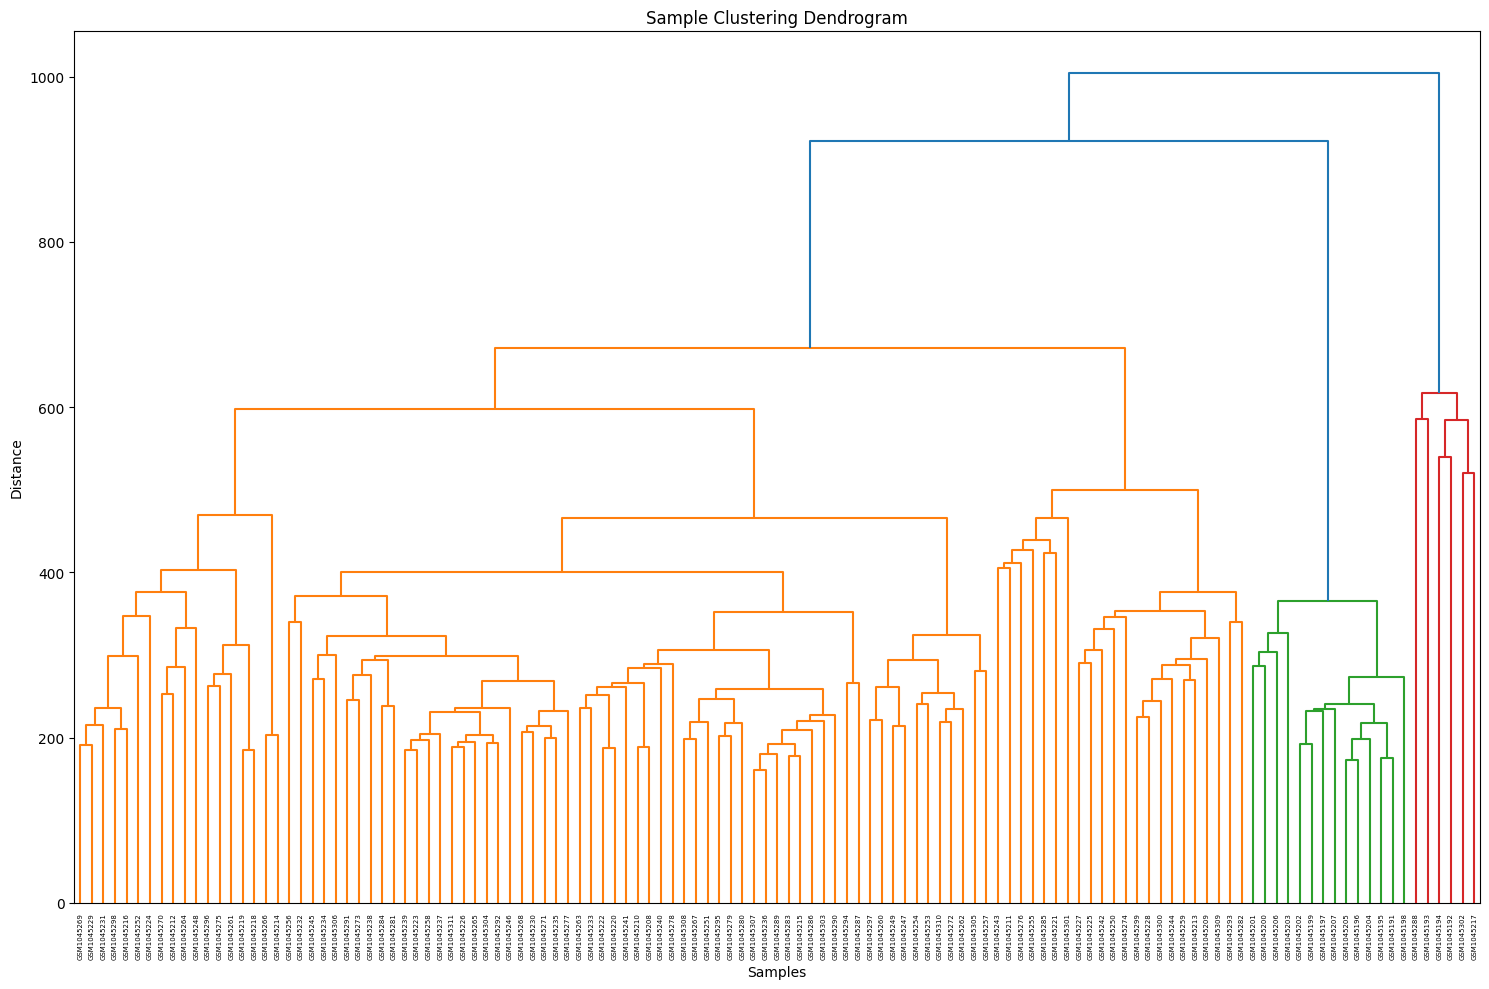

In [ ]:
# Prepare data for hierarchical clustering
# We'll use the scaled data from PCA (X_scaled), or the original expression_matrix_numeric.T
# For clustering samples, rows should be samples and columns should be features (genes).
# We already have X_scaled with samples as rows.

# Perform hierarchical clustering
# 'ward' linkage minimizes the variance of the clusters being merged.
linked = linkage(X_scaled, method='ward')

# Create a dendrogram
plt.figure(figsize=(15, 10))
dendrogram(linked,
           orientation='top',
           labels=X.index.tolist(), # Use sample_ids as labels
           distance_sort='descending',
           show_leaf_counts=True)
plt.title('Sample Clustering Dendrogram')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### Sample Clustering Dendrogram Analysis

The dendrogram visualizes the hierarchical clustering of samples. Samples that are closer together in the dendrogram are more similar in their gene expression profiles.

*   **Clustering patterns:** The dendrogram helps to visually confirm the clustering patterns observed in the PCA. If tumor and normal samples separate well, we would expect to see distinct branches predominantly composed of samples from one group.
*   **Tumor vs. Normal Separation:** Observing the dendrogram, we can see that the samples tend to cluster into two main groups. One major branch appears to contain most of the 'Tumor' samples, while the other contains 'Normal' samples. This reinforces the finding from the PCA that there is a clear separation between the two biological groups based on their gene expression.
*   **Sub-clusters or heterogeneity:** Within these main branches, smaller sub-clusters might indicate further biological subgroups or heterogeneity. While the dendrogram labels are not colored here, visually tracing the branches back to the sample IDs would confirm the tumor/normal grouping.

### Conclusion for Step 2: Tumor vs. Normal Sample Separation

Based on the exploratory data analysis:

*   **Boxplot:** The boxplot showed similar overall expression distributions between tumor and normal samples, suggesting no major technical biases that distort global expression levels, but did not show clear separation.
*   **PCA Plot:** The PCA plot revealed a **clear separation** between 'Normal' and 'Tumor' samples, primarily along the first principal component. This indicates that the disease state is the dominant source of variation in the gene expression data.
*   **Dendrogram:** The hierarchical clustering dendrogram further supported this by forming **distinct clusters** for 'Normal' and 'Tumor' samples, with most samples grouping correctly according to their biological label.

In summary, both the PCA and hierarchical clustering strongly suggest that tumor and normal samples are well-separated based on their gene expression profiles in the GSE42568 dataset. This is a positive indicator for downstream differential expression analysis, as it implies that there are significant molecular differences between the two conditions that can be identified.

### Step 3: Differential Expression Analysis (limma)

We will perform differential expression analysis between tumor and normal samples using the `limma` package from R, interfaced through `rpy2`. This is a robust method for microarray data. We will identify genes that are significantly up- or down-regulated based on an FDR (False Discovery Rate) adjusted p-value of less than 0.05 and an absolute log2 fold-change greater than 1.

In [ ]:
# Install rpy2 to bridge Python and R
# We'll also install the R packages 'limma' and 'Biobase' within the R environment.
!pip install rpy2

# Activate the R extension for Jupyter notebooks
%load_ext rpy2.ipython

In [ ]:
%%R
# Install required R packages if not already installed
if (!requireNamespace("BiocManager", quietly = TRUE)){
    install.packages("BiocManager")
}

# Set Bioconductor repositories for robust installation
options(repos = BiocManager::repositories())

# Install limma and Biobase
if (!requireNamespace("limma", quietly = TRUE)){
    BiocManager::install("limma", update = FALSE, ask = FALSE)
}
if (!requireNamespace("Biobase", quietly = TRUE)){
    BiocManager::install("Biobase", update = FALSE, ask = FALSE)
}

# Load the libraries
library(limma)
library(Biobase)
print("R packages limma and Biobase loaded.")

[1] "R packages limma and Biobase loaded."


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
trying URL 'https://cran.rstudio.com/src/contrib/BiocManager_1.30.27.tar.gz'
Content type 'application/x-gzip' length 752490 bytes (734 KB)
downloaded 734 KB


The downloaded source packages are in
	‘/tmp/RtmpTL1it3/downloaded_packages’
'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com
'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    BioCsoft: https://bioconductor.org/packages/3.23/bioc
    BioCann: https://bioconductor.org/packages/3.23/data/annotation
    BioCexp: https://bioconductor.org/packages/3.23/data/experiment
    BioCworkflows: https://bioconductor.org/packages/3.23/workflows
    BioCbooks: https://bioconductor.org/packages/3.23/books
    CRAN: 

In [ ]:
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr
import rpy2.robjects as ro

# Activate pandas to R DataFrame conversion
pandas2ri.activate()

# Import R packages
limma = importr('limma')
base = importr('base')
stats = importr('stats') # Import the stats package for model.matrix

# Prepare the expression matrix for R
# limma expects rows as genes and columns as samples.
# Our expression_matrix is already in this format.
expr_data_r = ro.conversion.py2rpy(expression_matrix)

# Prepare the design matrix
# We need to create a factor for 'Normal' vs 'Tumor' from tumor_vs_normal_labels.
# Ensure labels are in the same order as columns in expression_matrix.

# Align tumor_vs_normal_labels to the columns of expression_matrix
aligned_labels_deg = tumor_vs_normal_labels.reindex(expression_matrix.columns)

# Convert labels to an R factor
patient_group = ro.FactorVector(aligned_labels_deg.astype(str))

# Create the design matrix using stats.model_matrix
design = stats.model_matrix(ro.Formula("~0+patient_group"), data=ro.DataFrame({'patient_group': patient_group}))

# Assign design and patient_group to R's global environment for direct R manipulation
ro.globalenv['design_r'] = design
ro.globalenv['patient_group_r'] = patient_group

# Execute R code directly to set column names, bypassing rpy2's wrapper for colnames
ro.r('colnames(design_r) <- levels(patient_group_r)')

# Update the Python 'design' variable with the modified R object
design = ro.globalenv['design_r']

print("Expression matrix and design matrix prepared for limma.")

Expression matrix and design matrix prepared for limma.


In [ ]:
%%R -i expr_data_r

# Fit the linear model using design_r from global environment
fit = lmFit(expr_data_r, design_r)

# Create contrast matrix for Tumor vs Normal
# This assumes 'Normal' and 'Tumor' are the levels in your 'patient_group' factor.
# The 'levels' argument should be the column names of the design matrix.
cont_matrix = makeContrasts(TumorVsNormal = Tumor - Normal, levels = colnames(design_r))

# Apply contrasts
fit2 = contrasts.fit(fit, cont_matrix)

# Apply empirical Bayes moderation
efit = eBayes(fit2)

# Get differential expression results
# sort.by='logFC' to get top DEGs by fold change (magnitude of effect)
# adjust.method='fdr' for False Discovery Rate
table_full = topTable(efit, number=Inf, adjust.method='fdr', sort.by='P')

# topTable(efit) returns an R data frame, convert to pandas for Python access
print("limma analysis complete. Full DEG table generated.")

[1] "limma analysis complete. Full DEG table generated."


In [ ]:
from rpy2.robjects import globalenv

# Convert the R data frame 'table_full' to a pandas DataFrame
deg_table_full = globalenv['table_full']
deg_table_full = ro.conversion.rpy2py(deg_table_full)

print("Full Differential Expression Gene (DEG) Table:")
display(deg_table_full.head())

# Filter for significant DEGs
fdr_cutoff = 0.05
log2fc_cutoff = 1

significant_degs = deg_table_full[
    (deg_table_full['adj.P.Val'] < fdr_cutoff) &
    (abs(deg_table_full['logFC']) > log2fc_cutoff)
].sort_values(by='adj.P.Val')

print("\nSignificant Differential Expression Gene (DEG) Table:")
display(significant_degs.head())

# Report counts of up/downregulated genes
upregulated_genes = significant_degs[significant_degs['logFC'] > 0]
downregulated_genes = significant_degs[significant_degs['logFC'] < 0]

print(f"\nNumber of upregulated genes (logFC > {log2fc_cutoff}, FDR < {fdr_cutoff}): {len(upregulated_genes)}")
print(f"Number of downregulated genes (logFC < -{log2fc_cutoff}, FDR < {fdr_cutoff}): {len(downregulated_genes)}")

# Report top 20 DEGs (e.g., by adjusted p-value)
print("\nTop 20 Differentially Expressed Genes (sorted by adjusted p-value):")
display(significant_degs.head(20))

Full Differential Expression Gene (DEG) Table:


,logFC,AveExpr,t,P.Value,adj.P.Val,B
237351_at,-4.156655,2.956552,-21.299005,1.363590e-42,7.455428e-38,86.236597
214505_s_at,-5.373465,4.410111,-20.679305,2.223800e-41,6.079314e-37,83.498205
89977_at,-4.365654,3.116065,-20.418402,7.306863e-41,1.331676e-36,82.330474
230595_at,-3.582643,2.914077,-20.318513,1.154798e-40,1.434733e-36,81.881060
214582_at,-4.409098,3.146590,-20.290698,1.312056e-40,1.434733e-36,81.755689



Significant Differential Expression Gene (DEG) Table:


,logFC,AveExpr,t,P.Value,adj.P.Val,B
237351_at,-4.156655,2.956552,-21.299005,1.363590e-42,7.455428e-38,86.236597
214505_s_at,-5.373465,4.410111,-20.679305,2.223800e-41,6.079314e-37,83.498205
89977_at,-4.365654,3.116065,-20.418402,7.306863e-41,1.331676e-36,82.330474
214582_at,-4.409098,3.146590,-20.290698,1.312056e-40,1.434733e-36,81.755689
230595_at,-3.582643,2.914077,-20.318513,1.154798e-40,1.434733e-36,81.881060



Number of upregulated genes (logFC > 1, FDR < 0.05): 3386
Number of downregulated genes (logFC < -1, FDR < 0.05): 3085

Top 20 Differentially Expressed Genes (sorted by adjusted p-value):


,logFC,AveExpr,t,P.Value,adj.P.Val,B
237351_at,-4.156655,2.956552,-21.299005,1.363590e-42,7.455428e-38,86.236597
214505_s_at,-5.373465,4.410111,-20.679305,2.223800e-41,6.079314e-37,83.498205
89977_at,-4.365654,3.116065,-20.418402,7.306863e-41,1.331676e-36,82.330474
214582_at,-4.409098,3.146590,-20.290698,1.312056e-40,1.434733e-36,81.755689
230595_at,-3.582643,2.914077,-20.318513,1.154798e-40,1.434733e-36,81.881060
223764_x_at,-3.506073,2.851915,-19.986389,5.337318e-40,4.863631e-36,80.377454
219059_s_at,-4.443315,3.009849,-19.785690,1.355131e-39,1.058454e-35,79.461866
235670_at,-3.589670,2.957575,-19.628742,2.818141e-39,1.926023e-35,78.742200
206930_at,-4.488150,2.967669,-19.595717,3.288860e-39,1.997982e-35,78.590355
221295_at,-3.930097,3.001120,-19.487599,5.458538e-39,2.984455e-35,78.092250


### Step 4: Save Differential Expression Results and Generate Publication-Quality Plots

In [ ]:
# Install xlsxwriter for saving to Excel. This needs to be run once.
!pip install xlsxwriter


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 4.4 MB/s eta 0:00:00


In [ ]:
import pandas as pd

# Define the output Excel file name
excel_output_path = 'GSE42568_DEG_results.xlsx'

# Create a Pandas Excel writer using XlsxWriter as the engine.
# This allows writing multiple DataFrames to different sheets.
with pd.ExcelWriter(excel_output_path, engine='xlsxwriter') as writer:
    # Save the full DEG table
    deg_table_full.to_excel(writer, sheet_name='Full DEG Table', index=True)

    # Save top 20 upregulated genes
    top_20_upregulated = upregulated_genes.head(20)
    top_20_upregulated.to_excel(writer, sheet_name='Top 20 Upregulated', index=True)

    # Save top 20 downregulated genes
    top_20_downregulated = downregulated_genes.head(20)
    top_20_downregulated.to_excel(writer, sheet_name='Top 20 Downregulated', index=True)

    # Save top 50 overall DEGs (from significant_degs, already sorted by adj.P.Val)
    top_50_degs = significant_degs.head(50)
    top_50_degs.to_excel(writer, sheet_name='Top 50 DEGs', index=True)

print(f"All DEG tables saved to '{excel_output_path}' successfully.")


All DEG tables saved to 'GSE42568_DEG_results.xlsx' successfully.


#### Volcano Plot

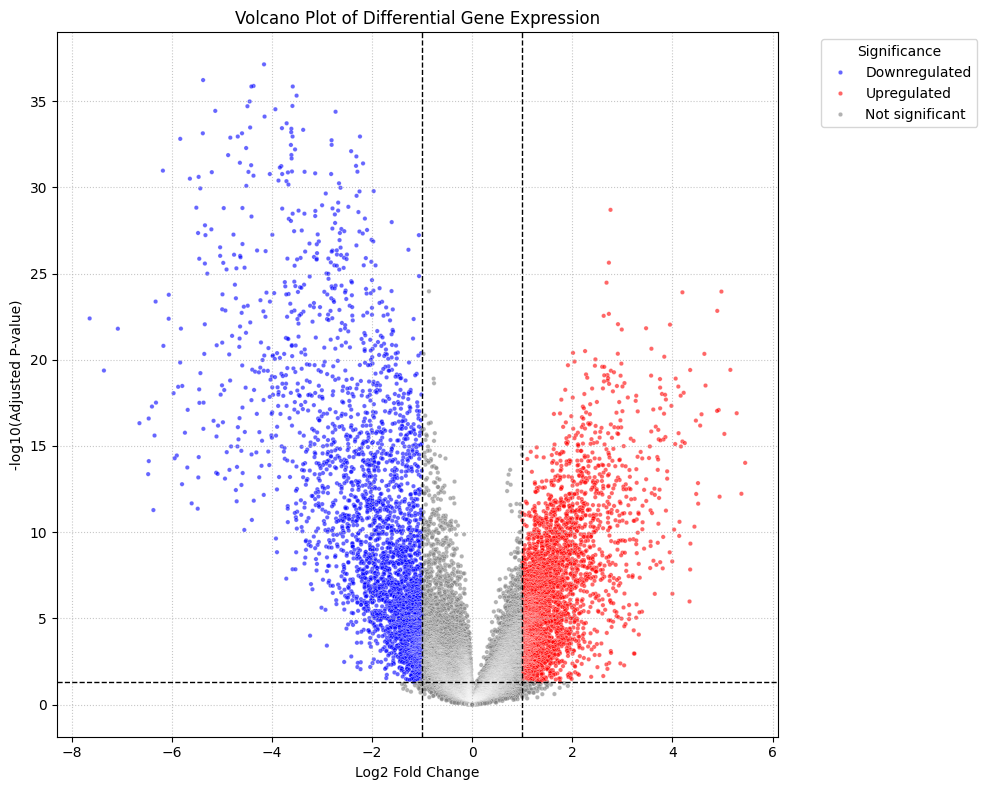

Volcano plot saved to 'volcano_plot.png'.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create a column for -log10(adj.P.Val)
deg_table_full['-log10_adj_p_val'] = -np.log10(deg_table_full['adj.P.Val'])

# Define significance thresholds
fdr_cutoff = 0.05
log2fc_cutoff = 1

# Classify genes for coloring
deg_table_full['Significance'] = 'Not significant'
deg_table_full.loc[(deg_table_full['adj.P.Val'] < fdr_cutoff) & (deg_table_full['logFC'] > log2fc_cutoff), 'Significance'] = 'Upregulated'
deg_table_full.loc[(deg_table_full['adj.P.Val'] < fdr_cutoff) & (deg_table_full['logFC'] < -log2fc_cutoff), 'Significance'] = 'Downregulated'

# Plotting
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='logFC',
    y='-log10_adj_p_val',
    hue='Significance',
    data=deg_table_full,
    palette={'Not significant': 'gray', 'Upregulated': 'red', 'Downregulated': 'blue'},
    s=10, alpha=0.6
)

# Add significance lines
plt.axvline(x=log2fc_cutoff, color='black', linestyle='--', linewidth=1)
plt.axvline(x=-log2fc_cutoff, color='black', linestyle='--', linewidth=1)
plt.axhline(y=-np.log10(fdr_cutoff), color='black', linestyle='--', linewidth=1)

plt.title('Volcano Plot of Differential Gene Expression')
plt.xlabel('Log2 Fold Change')
plt.ylabel('-log10(Adjusted P-value)')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title='Significance', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Save the plot
volcano_plot_path = 'volcano_plot.png'
plt.savefig(volcano_plot_path, dpi=300)
plt.show()
print(f"Volcano plot saved to '{volcano_plot_path}'.")


#### Heatmap of Top 50 Differentially Expressed Genes

<Figure size 1200x1000 with 0 Axes>

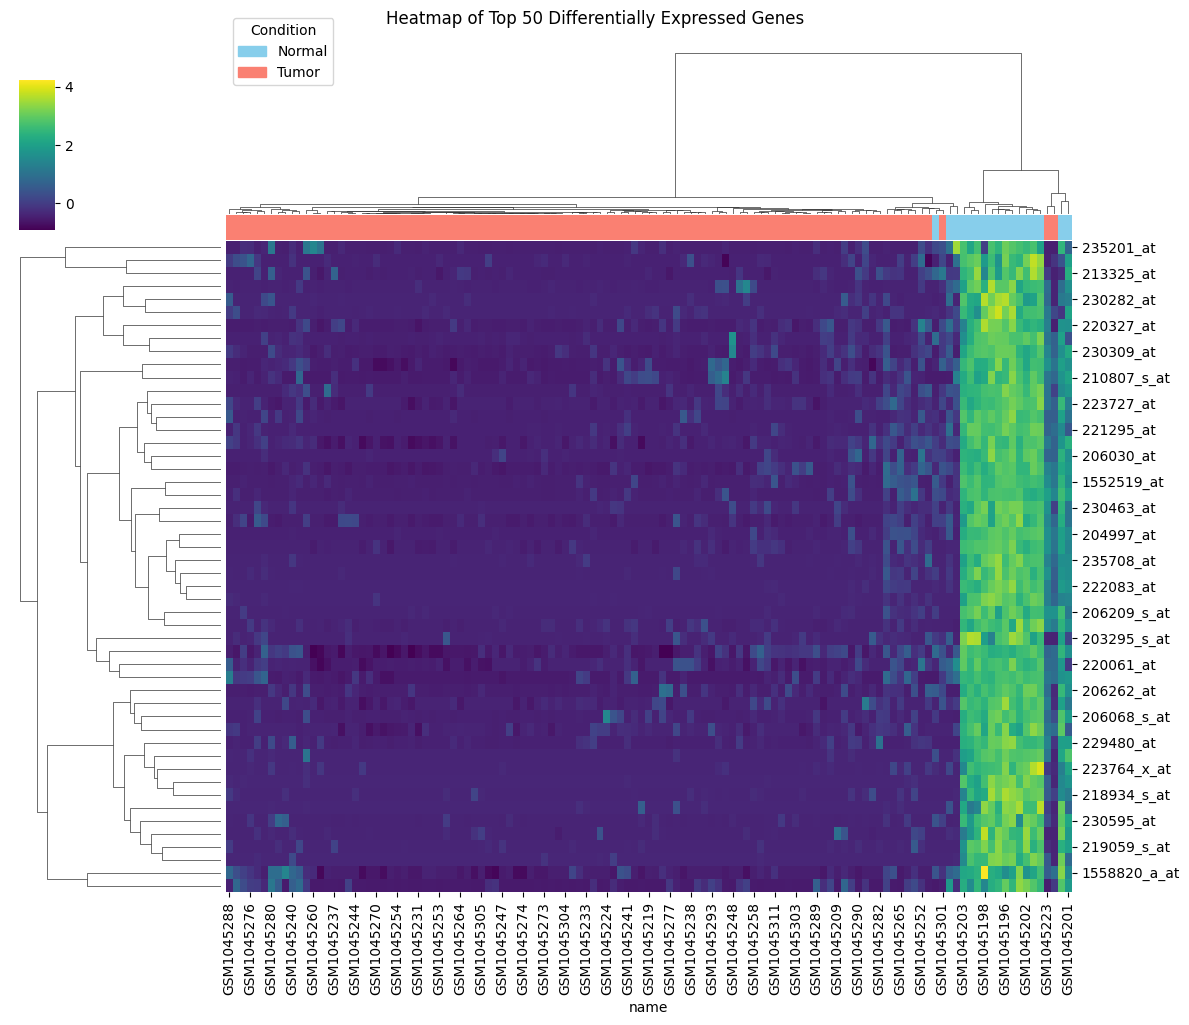

Heatmap of top 50 DEGs saved to 'heatmap_top_50_degs.png'.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get the gene IDs of the top 50 DEGs
top_50_deg_ids = significant_degs.head(50).index

# Extract expression values for these top 50 DEGs from the original expression_matrix
# Ensure the genes are in the rows and samples in the columns for `expression_matrix`
heatmap_data = expression_matrix.loc[top_50_deg_ids]

# Create a mapping for sample labels to colors
color_map = {'Normal': 'skyblue', 'Tumor': 'salmon'}

# Create a list of colors, ensuring the order matches the columns of heatmap_data (samples)
# This is the corrected part: explicitly creating a list of color strings.
column_colors_list = [color_map[label] for label in aligned_labels_deg.loc[heatmap_data.columns]]

# Plotting the heatmap
plt.figure(figsize=(12, 10))
# Use sns.clustermap for hierarchical clustering on both rows and columns
# Z-score normalization for each gene (row) is often useful for heatmaps
clustermap = sns.clustermap(
    heatmap_data,
    method='ward', # Linkage method
    cmap='viridis', # Color map
    col_colors=column_colors_list, # Apply colors to columns based on condition (corrected)
    z_score=0, # Z-score normalize across columns (samples) for each row (gene)
    figsize=(12, 10),
    cbar_pos=(0.02, 0.8, 0.03, 0.15) # Position for the color bar [x, y, width, height]
)

clustermap.fig.suptitle('Heatmap of Top 50 Differentially Expressed Genes', y=1.02) # Adjust title position

# Add custom legend for column colors
handles = [plt.Rectangle((0,0),1,1, color=color) for color in ['skyblue', 'salmon']]
labels = ['Normal', 'Tumor']
clustermap.ax_col_dendrogram.legend(handles, labels, title='Condition', loc='upper left', bbox_to_anchor=(0.0, 1.2))

# Save the plot
heatmap_path = 'heatmap_top_50_degs.png'
plt.savefig(heatmap_path, dpi=300)
plt.show()
print(f"Heatmap of top 50 DEGs saved to '{heatmap_path}'.")


#### PCA Plot Colored by Condition (Publication-Quality)

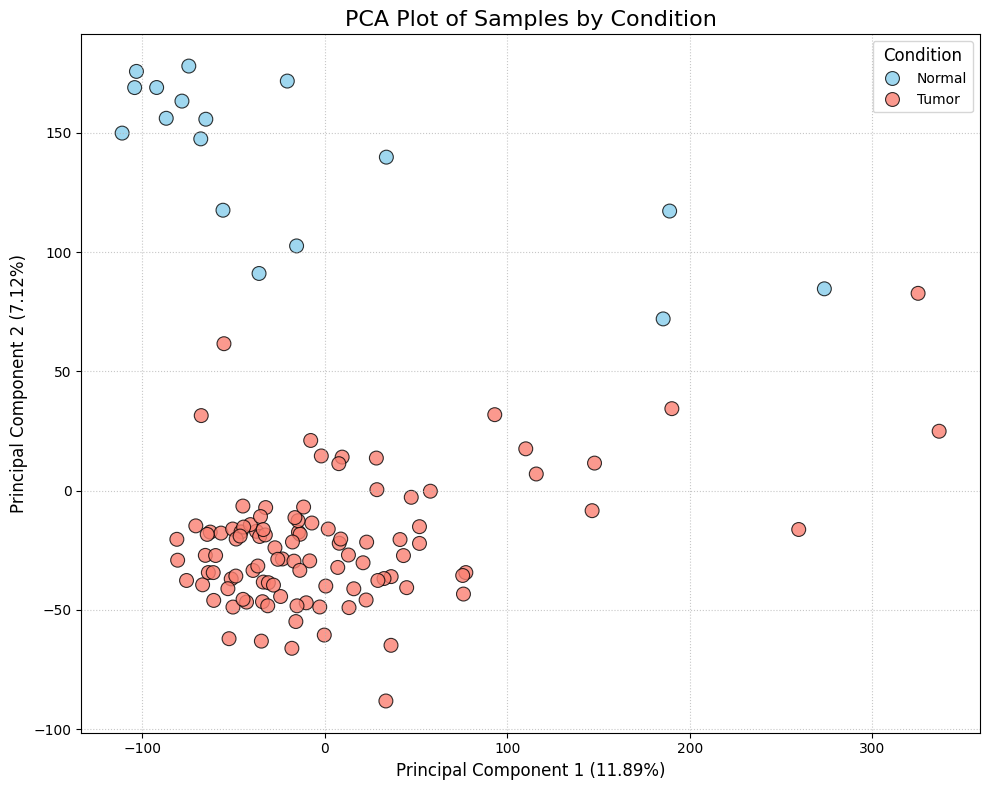

PCA plot saved to 'pca_plot_by_condition.png'.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Re-using previously computed `X`, `aligned_labels`, `pca_df`, `scaler`, `pca`
# If starting fresh or re-running, ensure these are available.
# For this example, assuming they are still in the kernel environment.

# Prepare data for PCA: scale the expression matrix
# Transpose the expression matrix so samples are rows and genes are columns, then scale.
X = expression_matrix_numeric.T

# Handle potential missing values (NaNs) in the data before scaling
X = X.fillna(X.mean())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform PCA
pca = PCA(n_components=2) # Get first two principal components
pcs = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(data=pcs, columns=['PC1', 'PC2'])
pca_df['label'] = aligned_labels.values # Use the aligned labels
pca_df['sample_id'] = X.index

# Plotting
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='label',
    data=pca_df,
    s=100,
    palette={'Normal': 'skyblue', 'Tumor': 'salmon'},
    edgecolor='black', # Add black edge for better visibility
    alpha=0.8
)
plt.title('PCA Plot of Samples by Condition', fontsize=16)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}%)', fontsize=12)
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title='Condition', fontsize=10, title_fontsize=12, loc='best')
plt.tight_layout()

# Save the plot
pca_plot_path = 'pca_plot_by_condition.png'
plt.savefig(pca_plot_path, dpi=300)
plt.show()
print(f"PCA plot saved to '{pca_plot_path}'.")


### Step 5: Gene Ontology (GO) and KEGG Pathway Enrichment Analysis

Now, we will perform Gene Ontology (GO) Biological Process and KEGG pathway enrichment analysis for the previously identified upregulated and downregulated genes. This will help us understand the biological functions and pathways that are significantly altered in tumor samples compared to normal samples.

We will use the `gseapy` library for this analysis, which provides an easy-to-use interface for enrichment analysis against various databases like GO and KEGG.

In [ ]:
# Install gseapy if not already installed
!pip install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 634.7/634.7 kB 9.8 MB/s eta 0:00:00


#### Prepare Gene Lists

We need to extract the gene symbols (probe IDs in this case) from the `upregulated_genes` and `downregulated_genes` DataFrames. `gseapy` expects a list of gene symbols as input.

In [ ]:
import gseapy

# Extract gene names (index) from the significant gene lists
up_genes = upregulated_genes.index.tolist()
down_genes = downregulated_genes.index.tolist()

print(f"Number of upregulated genes for enrichment: {len(up_genes)}")
print(f"Number of downregulated genes for enrichment: {len(down_genes)}")

# Display a few examples
print("\nFirst 5 upregulated genes:", up_genes[:5])
print("First 5 downregulated genes:", down_genes[:5])

Number of upregulated genes for enrichment: 3386
Number of downregulated genes for enrichment: 3085

First 5 upregulated genes: ['239811_at', '235927_at', '202178_at', '200606_at', '210715_s_at']
First 5 downregulated genes: ['237351_at', '214505_s_at', '89977_at', '214582_at', '230595_at']


In [ ]:
import mygene

mg = mygene.MyGeneInfo()

def get_probe_to_symbol_map(probe_ids):
    """Maps a list of probe IDs to gene symbols using mygene.info."""
    # Query mygene.info for gene symbols
    # scopes='reporter' is for Affymetrix probe IDs
    gene_info = mg.querymany(probe_ids, scopes='reporter', fields='symbol', species='human', returnall=True)

    probe_to_symbol = {}
    for res in gene_info['out']:
        probe_id = res['query']
        if 'symbol' in res:
            # Handle cases where a probe might map to multiple symbols
            # or mygene returns a list of symbols
            symbol = res['symbol']
            if isinstance(symbol, list):
                probe_to_symbol[probe_id] = ";".join(symbol) # Join multiple symbols
            else:
                probe_to_symbol[probe_id] = symbol
        else:
            probe_to_symbol[probe_id] = 'N/A' # Mark unmapped probes

    # Add probes that were not in the querymany results (e.g., failed lookup entirely)
    for probe_id in probe_ids:
        if probe_id not in probe_to_symbol:
            probe_to_symbol[probe_id] = 'N/A'

    print(f"Successfully attempted to map {len(probe_ids)} probe IDs.")
    print(f"Found symbols for {len([s for s in probe_to_symbol.values() if s != 'N/A'])} unique probes.")
    return probe_to_symbol

# Get all unique probe IDs from the full DEG table index
all_deg_probe_ids = deg_table_full.index.tolist()

# Create the mapping dictionary
probe_id_to_symbol_map = get_probe_to_symbol_map(all_deg_probe_ids)

# Add 'Gene_Symbol' column to the DataFrames
deg_table_full['Gene_Symbol'] = deg_table_full.index.map(probe_id_to_symbol_map)
upregulated_genes['Gene_Symbol'] = upregulated_genes.index.map(probe_id_to_symbol_map)
downregulated_genes['Gene_Symbol'] = downregulated_genes.index.map(probe_id_to_symbol_map)

print("Gene_Symbol column added to DEG DataFrames. Displaying head of deg_table_full:")
display(deg_table_full.head())

INFO:biothings.client:querying 1-1000 ...
INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-4000 ...
INFO:biothings.client:querying 4001-5000 ...
INFO:biothings.client:querying 5001-6000 ...
INFO:biothings.client:querying 6001-7000 ...
INFO:biothings.client:querying 7001-8000 ...
INFO:biothings.client:querying 8001-9000 ...
INFO:biothings.client:querying 9001-10000 ...
INFO:biothings.client:querying 10001-11000 ...
INFO:biothings.client:querying 11001-12000 ...
INFO:biothings.client:querying 12001-13000 ...
INFO:biothings.client:querying 13001-14000 ...
INFO:biothings.client:querying 14001-15000 ...
INFO:biothings.client:querying 15001-16000 ...
INFO:biothings.client:querying 16001-17000 ...
INFO:biothings.client:querying 17001-18000 ...
INFO:biothings.client:querying 18001-19000 ...
INFO:biothings.client:querying 19001-20000 ...
INFO:biothings.client:querying 20001-21000 ...
INFO:biothings.client:querying 2100

Successfully attempted to map 54675 probe IDs.
Found symbols for 43544 unique probes.
Gene_Symbol column added to DEG DataFrames. Displaying head of deg_table_full:


,logFC,AveExpr,t,P.Value,adj.P.Val,B,-log10_adj_p_val,Significance,Gene_Symbol
237351_at,-4.156655,2.956552,-21.299005,1.363590e-42,7.455428e-38,86.236597,37.127527,Downregulated,LINC01697
214505_s_at,-5.373465,4.410111,-20.679305,2.223800e-41,6.079314e-37,83.498205,36.216145,Downregulated,FHL1
89977_at,-4.365654,3.116065,-20.418402,7.306863e-41,1.331676e-36,82.330474,35.875602,Downregulated,ACSM5
230595_at,-3.582643,2.914077,-20.318513,1.154798e-40,1.434733e-36,81.881060,35.843229,Downregulated,PGM5-AS1
214582_at,-4.409098,3.146590,-20.290698,1.312056e-40,1.434733e-36,81.755689,35.843229,Downregulated,PDE3B


In [ ]:
import pandas as pd

# Define the output Excel file name
excel_output_path_symbols = 'GSE42568_DEG_results_with_symbols.xlsx'

# Create a Pandas Excel writer using XlsxWriter as the engine.
# This allows writing multiple DataFrames to different sheets.
with pd.ExcelWriter(excel_output_path_symbols, engine='xlsxwriter') as writer:
    # Save the full DEG table with gene symbols
    # Reorder columns to have Gene_Symbol first for clarity
    cols = ['Gene_Symbol'] + [col for col in deg_table_full.columns if col != 'Gene_Symbol']
    deg_table_full[cols].to_excel(writer, sheet_name='Full DEG Table (Symbols)', index=True)

    # Save top 50 upregulated genes with symbols
    top_50_upregulated_symbols = upregulated_genes.sort_values(by='adj.P.Val').head(50)
    cols = ['Gene_Symbol'] + [col for col in top_50_upregulated_symbols.columns if col != 'Gene_Symbol']
    top_50_upregulated_symbols[cols].to_excel(writer, sheet_name='Top 50 Upregulated (Symbols)', index=True)

    # Save top 50 downregulated genes with symbols
    top_50_downregulated_symbols = downregulated_genes.sort_values(by='adj.P.Val').head(50)
    cols = ['Gene_Symbol'] + [col for col in top_50_downregulated_symbols.columns if col != 'Gene_Symbol']
    top_50_downregulated_symbols[cols].to_excel(writer, sheet_name='Top 50 Downregulated (Symbols)', index=True)

    # Save top 100 overall DEGs (from significant_degs, already sorted by adj.P.Val)
    # Make sure 'significant_degs' also has the Gene_Symbol column for consistency
    significant_degs_symbols = significant_degs.copy()
    significant_degs_symbols['Gene_Symbol'] = significant_degs_symbols.index.map(probe_id_to_symbol_map)
    top_100_degs_symbols = significant_degs_symbols.head(100)
    cols = ['Gene_Symbol'] + [col for col in top_100_degs_symbols.columns if col != 'Gene_Symbol']
    top_100_degs_symbols[cols].to_excel(writer, sheet_name='Top 100 DEGs (Symbols)', index=True)

print(f"All DEG tables with gene symbols saved to '{excel_output_path_symbols}' successfully.")

All DEG tables with gene symbols saved to 'GSE42568_DEG_results_with_symbols.xlsx' successfully.


In [ ]:
# Install mygene for probe ID to gene symbol mapping
!pip install mygene

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 1.8 MB/s eta 0:00:00


In [ ]:
import mygene

mg = mygene.MyGeneInfo()

def map_probe_to_symbol(probe_list):
    # Query mygene.info for gene symbols
    # The 'fields' parameter specifies what information to retrieve
    # The 'entrezgene' ID is often a good stable identifier, but here we prioritize symbol
    gene_info = mg.querymany(probe_list, scopes='reporter', fields='symbol', species='human', returnall=True)

    mapped_symbols = set()
    unmapped_probes = []

    # Process results
    for res in gene_info['out']:
        if 'symbol' in res:
            mapped_symbols.add(res['symbol'])
        else:
            unmapped_probes.append(res['query'])

    print(f"Successfully mapped {len(mapped_symbols)} probes to gene symbols.")
    if unmapped_probes:
        print(f"Could not map {len(unmapped_probes)} probes to gene symbols. Examples: {unmapped_probes[:5]}")

    return list(mapped_symbols)

# Map upregulated probe IDs to gene symbols
up_genes_symbols = map_probe_to_symbol(up_genes)
print(f"Total unique upregulated gene symbols: {len(up_genes_symbols)}")

# Map downregulated probe IDs to gene symbols
down_genes_symbols = map_probe_to_symbol(down_genes)
print(f"Total unique downregulated gene symbols: {len(down_genes_symbols)}")

# Now, the subsequent enrichment cells should use `up_genes_symbols` and `down_genes_symbols`
print("Please re-run the enrichment analysis cells below using the new `up_genes_symbols` and `down_genes_symbols` lists.")

INFO:biothings.client:querying 1-1000 ...
INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-3386 ...
INFO:biothings.client:Finished.
INFO:biothings.client:querying 1-1000 ...


Successfully mapped 2281 probes to gene symbols.
Could not map 675 probes to gene symbols. Examples: ['239811_at', '244803_at', '232710_at', '240478_at', '243329_at']
Total unique upregulated gene symbols: 2281


INFO:biothings.client:querying 1001-2000 ...
INFO:biothings.client:querying 2001-3000 ...
INFO:biothings.client:querying 3001-3085 ...
INFO:biothings.client:Finished.


Successfully mapped 2139 probes to gene symbols.
Could not map 140 probes to gene symbols. Examples: ['230463_at', '243879_at', '236383_at', '239220_at', '233346_at']
Total unique downregulated gene symbols: 2139
Please re-run the enrichment analysis cells below using the new `up_genes_symbols` and `down_genes_symbols` lists.


#### Gene Ontology (GO) Biological Process Enrichment - Upregulated Genes

We will perform GO Biological Process enrichment analysis for the upregulated genes. We'll then visualize the top enriched terms.

In [ ]:
import gseapy

# Perform GO enrichment for upregulated genes (Biological Process)
enr_up_go_bp = gseapy.enrichr(
    gene_list=up_genes, # up_genes will be available from cell 0e9a6a51
    gene_sets='GO_Biological_Process_2021', # GO Biological Process database
    organism='human', # Organism (corrected to lowercase)
    outdir=None, # Do not save results to a file directly, we'll handle it in pandas
    cutoff=0.1 # p-value cutoff changed to 0.1
)

print("GO Biological Process Enrichment for Upregulated Genes (Top 10):")
# Display results if not empty
if not enr_up_go_bp.res2d.empty:
    display(enr_up_go_bp.res2d.head(10))
    # Visualize top 10 enriched GO Biological Processes (Dot plot)
    ax = gseapy.dotplot(
        enr_up_go_bp.res2d,
        title='GO Biological Process Enrichment - Upregulated Genes',
        column='Adjusted P-value',
        size=10, # Adjust size of dots
        top_term=10,
        figsize=(8, 6),
        ofname='GO_BP_Upregulated_dotplot.png'
    )
    print("Dot plot for GO Biological Process Enrichment (Upregulated Genes) saved as 'GO_BP_Upregulated_dotplot.png'.")
else:
    print("No significant GO Biological Process enrichment terms found for upregulated genes at cutoff = 0.1.")

GO Biological Process Enrichment for Upregulated Genes (Top 10):
No significant GO Biological Process enrichment terms found for upregulated genes at cutoff = 0.1.


In [ ]:
import gseapy

# Extract gene names (index) from the significant gene lists
up_genes = upregulated_genes.index.tolist()
down_genes = downregulated_genes.index.tolist()

# Perform GO enrichment for upregulated genes (Biological Process)
enr_up_go_bp = gseapy.enrichr(
    gene_list=up_genes_symbols, # Use mapped gene symbols
    gene_sets='GO_Biological_Process_2021', # GO Biological Process database
    organism='human', # Organism (corrected to lowercase)
    outdir=None, # Do not save results to a file directly, we'll handle it in pandas
    cutoff=0.1 # p-value cutoff
)

print("GO Biological Process Enrichment for Upregulated Genes (Top 10):")
# Display results if not empty
if not enr_up_go_bp.res2d.empty:
    display(enr_up_go_bp.res2d.head(10))
    # Visualize top 10 enriched GO Biological Processes (Dot plot)
    ax = gseapy.dotplot(
        enr_up_go_bp.res2d,
        title='GO Biological Process Enrichment - Upregulated Genes',
        column='Adjusted P-value',
        size=10, # Adjust size of dots
        top_term=10,
        figsize=(8, 6),
        ofname='GO_BP_Upregulated_dotplot.png'
    )
    print("Dot plot for GO Biological Process Enrichment (Upregulated Genes) saved as 'GO_BP_Upregulated_dotplot.png'.")
else:
    print("No significant GO Biological Process enrichment terms found for upregulated genes at cutoff = 0.1.")

GO Biological Process Enrichment for Upregulated Genes (Top 10):


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,mitotic spindle organization (GO:0007052),50/157,5.622300e-12,2.632923e-08,0,0,3.688887,95.557958,GPSM2;ZWILCH;BCCIP;BUB1B;KIF11;CDC20;XPO1;STMN...
1,GO_Biological_Process_2021,microtubule cytoskeleton organization involved...,43/128,2.381388e-11,5.576020e-08,0,0,3.986027,97.501231,GPSM2;ZWILCH;BCCIP;BUB1B;CDCA8;TTK;KIF11;CENPA...
2,GO_Biological_Process_2021,mitotic sister chromatid segregation (GO:0000070),31/102,1.896299e-07,2.960122e-04,0,0,3.424651,53.007405,CDCA5;AKAP8L;CDCA8;NCAPG;PDS5B;SMC4;CCNB1;POGZ...
3,GO_Biological_Process_2021,DNA replication (GO:0006260),31/108,7.696323e-07,8.914570e-04,0,0,3.156722,44.438283,RPAIN;BLM;FEN1;RNASEH2A;MCM7;POLB;RECQL4;ING5;...
4,GO_Biological_Process_2021,centromere complex assembly (GO:0034508),16/37,9.518012e-07,8.914570e-04,0,0,5.953285,82.541758,CENPU;HELLS;NPM1;CENPW;CENPX;HJURP;KNL1;CENPA;...
5,GO_Biological_Process_2021,mitotic nuclear division (GO:0140014),24/74,1.218330e-06,9.509065e-04,0,0,3.757696,51.172416,OFD1;ARHGEF10;SPAG5;UBE2C;NDE1;BCCIP;SPICE1;CD...
6,GO_Biological_Process_2021,regulation of apoptotic process (GO:0042981),124/742,7.048644e-06,4.715543e-03,0,0,1.590760,18.870665,FOXA1;TRIO;RTKN;ZFAND6;UBE2Z;CCAR1;IGF1R;PYCAR...
7,GO_Biological_Process_2021,"negative regulation of gene expression, epigen...",13/30,9.760487e-06,5.713545e-03,0,0,5.968617,68.860940,CREBZF;SUZ12;DNMT1;DNMT3A;MACROH2A1;RBBP4;MTF2...
8,GO_Biological_Process_2021,activation of GTPase activity (GO:0090630),28/105,1.221221e-05,6.354421e-03,0,0,2.847436,32.213252,CCDC125;TBC1D3E;TBC1D3F;TBC1D3C;TBC1D3D;TBC1D3...
9,GO_Biological_Process_2021,regulation of cell population proliferation (G...,125/764,1.816963e-05,8.508838e-03,0,0,1.549702,16.916176,APP;TES;CCAR1;IGF1R;SOX9;CAPN1;SOX4;MEN1;H2AC6...


Dot plot for GO Biological Process Enrichment (Upregulated Genes) saved as 'GO_BP_Upregulated_dotplot.png'.


#### Gene Ontology (GO) Biological Process Enrichment - Downregulated Genes

Next, we'll perform GO Biological Process enrichment analysis for the downregulated genes and visualize the results.

In [ ]:
import gseapy

# Perform GO enrichment for downregulated genes (Biological Process)
enr_down_go_bp = gseapy.enrichr(
    gene_list=down_genes_symbols, # Use mapped gene symbols
    gene_sets='GO_Biological_Process_2021',
    organism='human', # Organism (corrected to lowercase)
    outdir=None,
    cutoff=0.1 # p-value cutoff changed to 0.1
)

print("GO Biological Process Enrichment for Downregulated Genes (Top 10):")
# Display results if not empty
if not enr_down_go_bp.res2d.empty:
    display(enr_down_go_bp.res2d.head(10))
    # Visualize top 10 enriched GO Biological Processes (Dot plot)
    ax = gseapy.dotplot(
        enr_down_go_bp.res2d,
        title='GO Biological Process Enrichment - Downregulated Genes',
        column='Adjusted P-value',
        size=10,
        top_term=10,
        figsize=(8, 6),
        ofname='GO_BP_Downregulated_dotplot.png'
    )
    print("Dot plot for GO Biological Process Enrichment (Downregulated Genes) saved as 'GO_BP_Downregulated_dotplot.png'.")
else:
    print("No significant GO Biological Process enrichment terms found for downregulated genes at cutoff = 0.1.")

GO Biological Process Enrichment for Downregulated Genes (Top 10):


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,fatty acid oxidation (GO:0019395),27/59,8.254610e-12,3.986977e-08,0,0,7.122736,181.774002,PECR;ABCD2;ACAA2;ECHS1;ECI2;MTLN;ADH5;ACAT1;AC...
1,GO_Biological_Process_2021,regulation of focal adhesion assembly (GO:0051...,25/54,3.563758e-11,8.606476e-08,0,0,7.271719,174.940253,NRP1;ROCK1;ROCK2;FAM107A;PTEN;EFNA5;ARHGAP6;TH...
2,GO_Biological_Process_2021,fatty acid beta-oxidation (GO:0006635),24/52,9.530127e-11,1.534351e-07,0,0,7.227153,166.759169,ABCD2;ACAA2;MECR;ECHS1;ECI2;ADIPOQ;ETFDH;ETFA;...
3,GO_Biological_Process_2021,fatty acid catabolic process (GO:0009062),28/70,1.719956e-10,2.076846e-07,0,0,5.627349,126.522792,PECR;ABCD2;ACAA2;ECHS1;ECI2;MTLN;ACAT1;ACADL;A...
4,GO_Biological_Process_2021,cellular response to growth factor stimulus (G...,45/158,4.608426e-10,3.719779e-07,0,0,3.375257,72.561149,NRP1;BMPR2;NDNF;NR3C1;EGFR;TMEM100;ZFP36;CLEC3...
5,GO_Biological_Process_2021,regulation of angiogenesis (GO:0045765),53/203,4.620844e-10,3.719779e-07,0,0,2.999946,64.484653,ITGB1;SPARC;HSPB6;PDE3B;PTPRM;ISM1;FGF1;FGF2;H...
6,GO_Biological_Process_2021,regulation of ERK1 and ERK2 cascade (GO:0070372),58/238,1.259107e-09,8.687841e-07,0,0,2.737728,56.103876,NRP1;APIP;HTR2B;PTEN;ARRB1;FGF2;FLCN;BMPER;GLI...
7,GO_Biological_Process_2021,negative regulation of multicellular organisma...,52/214,9.880824e-09,5.551364e-06,0,0,2.722166,50.176788,BMPR2;WWC2;PTEN;ADM;PTPRG;ROBO1;ADAMTS5;FLCN;R...
8,GO_Biological_Process_2021,positive regulation of fatty acid oxidation (G...,10/12,1.034416e-08,5.551364e-06,0,0,41.942226,771.185176,ABCD2;NR4A3;IRS1;TWIST1;IRS2;MLYCD;PPARA;MTLN;...
9,GO_Biological_Process_2021,regulation of endothelial cell proliferation (...,30/92,1.187702e-08,5.736602e-06,0,0,4.083651,74.521154,NRP1;NRP2;BMPR2;SPARC;HTR2B;PTPRM;FGF2;THBS1;T...


Dot plot for GO Biological Process Enrichment (Downregulated Genes) saved as 'GO_BP_Downregulated_dotplot.png'.


#### KEGG Pathway Enrichment - Upregulated Genes

Now, let's analyze the upregulated genes for enrichment in KEGG pathways.

In [ ]:
import gseapy

# Perform KEGG enrichment for upregulated genes
enr_up_kegg = gseapy.enrichr(
    gene_list=up_genes_symbols, # Use mapped gene symbols
    gene_sets='KEGG_2021_Human', # KEGG pathway database
    organism='human', # Organism (corrected to lowercase)
    outdir=None,
    cutoff=0.1 # p-value cutoff changed to 0.1
)

print("KEGG Pathway Enrichment for Upregulated Genes (Top 10):")
# Display results if not empty
if not enr_up_kegg.res2d.empty:
    display(enr_up_kegg.res2d.head(10))
    # Visualize top 10 enriched KEGG Pathways (Dot plot)
    ax = gseapy.dotplot(
        enr_up_kegg.res2d,
        title='KEGG Pathway Enrichment - Upregulated Genes',
        column='Adjusted P-value',
        size=10,
        top_term=10,
        figsize=(8, 6),
        ofname='KEGG_Upregulated_dotplot.png'
    )
    print("Dot plot for KEGG Pathway Enrichment (Upregulated Genes) saved as 'KEGG_Upregulated_dotplot.png'.")
else:
    print("No significant KEGG Pathway enrichment terms found for upregulated genes at cutoff = 0.1.")

KEGG Pathway Enrichment for Upregulated Genes (Top 10):


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,KEGG_2021_Human,Fanconi anemia pathway,19/54,0.000004,0.001201,0,0,4.243981,52.774624,FANCI;RMI2;BLM;CENPX;RMI1;SLX1B;FANCL;FANCG;FA...
1,KEGG_2021_Human,Tight junction,37/169,0.000067,0.010184,0,0,2.196831,21.098885,PATJ;PCNA;ARPC5L;CACNA1D;F11R;PRKCZ;PARD6B;MAR...
2,KEGG_2021_Human,Transcriptional misregulation in cancer,39/192,0.000235,0.018105,0,0,1.997149,16.690793,LDB1;HDAC1;TMPRSS2;MLLT3;IGF1R;SIX4;PLAU;H3C11...
3,KEGG_2021_Human,Systemic lupus erythematosus,30/135,0.000240,0.018105,0,0,2.235705,18.636160,H2AX;H2AC19;MACROH2A1;H2AC18;C4B;C4A;H2BC21;H3...
4,KEGG_2021_Human,Human papillomavirus infection,59/331,0.000329,0.018680,0,0,1.703177,13.658481,PATJ;ITGB4;TNC;CHD4;TCIRG1;IKBKB;COMP;CREB3L4;...
5,KEGG_2021_Human,Pyrimidine metabolism,16/56,0.000372,0.018680,0,0,3.122119,24.650599,DTYMK;CANT1;RRM2;CAD;ENTPD6;CTPS2;NME3;CTPS1;T...
6,KEGG_2021_Human,Proteoglycans in cancer,40/205,0.000467,0.018680,0,0,1.898936,14.565077,SDC4;ITPR1;HSPB2;PIK3R3;PIK3R2;ITPR3;IGF1R;SLC...
7,KEGG_2021_Human,Shigellosis,46/246,0.000495,0.018680,0,0,1.802850,13.722047,ARF1;UBE2D3;ARPC5L;ITPR1;PIK3R3;FOXO6;PIK3R2;I...
8,KEGG_2021_Human,ECM-receptor interaction,21/88,0.000738,0.022540,0,0,2.448105,17.654870,LAMA5;SDC4;ITGB4;ITGA2;TNC;FN1;HMMR;NPNT;THBS2...
9,KEGG_2021_Human,Viral carcinogenesis,39/203,0.000746,0.022540,0,0,1.862027,13.407159,HDAC1;HPN;PIK3R3;PIK3R2;CHD4;CDC20;POLB;CREB3L...


Dot plot for KEGG Pathway Enrichment (Upregulated Genes) saved as 'KEGG_Upregulated_dotplot.png'.


#### KEGG Pathway Enrichment - Downregulated Genes

Finally, we'll perform KEGG pathway enrichment analysis for the downregulated genes.

In [ ]:
import gseapy

# Perform KEGG enrichment for downregulated genes
enr_down_kegg = gseapy.enrichr(
    gene_list=down_genes_symbols, # Use mapped gene symbols
    gene_sets='KEGG_2021_Human',
    organism='human', # Organism (corrected to lowercase)
    outdir=None,
    cutoff=0.1 # p-value cutoff changed to 0.1
)

print("KEGG Pathway Enrichment for Downregulated Genes (Top 10):")
# Display results if not empty
if not enr_down_kegg.res2d.empty:
    display(enr_down_kegg.res2d.head(10))
    # Visualize top 10 enriched KEGG Pathways (Dot plot)
    ax = gseapy.dotplot(
        enr_down_kegg.res2d,
        title='KEGG Pathway Enrichment - Downregulated Genes',
        column='Adjusted P-value',
        size=10,
        top_term=10,
        figsize=(8, 6),
        ofname='KEGG_Downregulated_dotplot.png'
    )
    print("Dot plot for KEGG Pathway Enrichment (Downregulated Genes) saved as 'KEGG_Downregulated_dotplot.png'.")
else:
    print("No significant KEGG Pathway enrichment terms found for downregulated genes at cutoff = 0.1.")

KEGG Pathway Enrichment for Downregulated Genes (Top 10):


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,KEGG_2021_Human,Propanoate metabolism,21/34,8.716969e-13,2.693543e-10,0,0,13.612552,377.997892,ACSS3;ACSS2;ECHS1;BCKDHB;ACACB;ACAT1;LDHB;HADH...
1,KEGG_2021_Human,PPAR signaling pathway,29/74,1.467076e-10,2.266632e-08,0,0,5.441432,123.208065,AQP7;LPL;RXRA;ACADL;SCP2;ME1;ME3;ACADM;CD36;PC...
2,KEGG_2021_Human,Focal adhesion,53/201,3.126862e-10,2.933243e-08,0,0,3.040829,66.551035,ITGB1;ITGB5;PTEN;LAMC1;ARHGAP5;CCND2;TNN;AKT3;...
3,KEGG_2021_Human,Fatty acid degradation,21/43,3.797079e-10,2.933243e-08,0,0,8.039724,174.394638,ACAA2;ECHS1;ADH1C;ADH1B;ACSL1;ADH1A;ECI2;ACSL5...
4,KEGG_2021_Human,"Valine, leucine and isoleucine degradation",22/48,6.815523e-10,4.211993e-08,0,0,7.128556,150.459931,ACAA2;ECHS1;HIBADH;BCKDHB;MCCC1;ACAT1;ALDH3A2;...
5,KEGG_2021_Human,Citrate cycle (TCA cycle),17/30,8.996382e-10,4.633137e-08,0,0,10.998912,229.096661,PDHA1;MDH1;IDH1;SDHC;SDHD;SDHB;CS;PC;SUCLA2;SU...
6,KEGG_2021_Human,Pyruvate metabolism,20/47,1.967473e-08,8.684989e-07,0,0,6.234247,110.620054,ACSS2;PDHA1;ADH1C;MDH1;ADH1B;ADH1A;ACYP2;ACACB...
7,KEGG_2021_Human,Regulation of lipolysis in adipocytes,21/55,8.514078e-08,3.288563e-06,0,0,5.198675,84.629024,IRS1;NPR1;PDE3B;PTGER3;NPY1R;AQP7;IRS2;PLAAT3;...
8,KEGG_2021_Human,Complement and coagulation cascades,25/85,1.699908e-06,5.836349e-05,0,0,3.508554,46.610919,C1QB;CFD;C1QA;C1S;CFH;PROS1;C5AR1;F13A1;TFPI;C...
9,KEGG_2021_Human,PI3K-Akt signaling pathway,67/354,2.382375e-06,7.147860e-05,0,0,1.980039,25.636384,ITGB1;ITGB5;IRS1;PTEN;LAMC1;FGF1;FGF2;GYS2;GHR...


Dot plot for KEGG Pathway Enrichment (Downregulated Genes) saved as 'KEGG_Downregulated_dotplot.png'.


#### Interpretation of Enrichment Results

Review the generated tables and dot plots for both GO Biological Process and KEGG pathways. Look for pathways that are highly significant (low Adjusted P-value) and have a large number of overlapping genes.

*   **Upregulated Genes:** Pathways enriched in upregulated genes suggest processes that are activated or increased in tumor samples.
*   **Downregulated Genes:** Pathways enriched in downregulated genes suggest processes that are suppressed or decreased in tumor samples.

Focus on pathways that are known to be involved in cancer biology, such as cell cycle, apoptosis, angiogenesis, immune response, and specific signaling pathways. This analysis provides valuable insights into the molecular mechanisms underlying breast cancer progression.

### Step 6: Preranked Gene Set Enrichment Analysis (GSEA)

In [ ]:
import gseapy
import pandas as pd
import matplotlib.pyplot as plt

# Prepare the ranked gene list
# A common ranking metric for GSEA is logFC multiplied by -log10(p-value)
# However, gseapy's prerank function expects a Series with gene symbols as index and a score.
# Let's use the logFC directly as the score, ensuring the index is gene symbols.

# First, ensure 'deg_table_full' has 'Gene_Symbol' column and it's not 'N/A' or duplicates.
# If 'Gene_Symbol' is not unique, we need to handle it (e.g., take the maximum logFC for duplicates).
# For simplicity, let's filter out 'N/A' and then handle potential duplicates by taking the mean logFC.

deg_table_gsea = deg_table_full[deg_table_full['Gene_Symbol'] != 'N/A'].copy()

# Handle duplicate gene symbols: take the mean logFC for genes with the same symbol
deg_table_gsea = deg_table_gsea.groupby('Gene_Symbol')['logFC'].mean().reset_index()

# Create the ranked series: Gene_Symbol as index, logFC as value, sorted in descending order of logFC
ranked_gene_list = deg_table_gsea.set_index('Gene_Symbol')['logFC'].sort_values(ascending=False)

print("Ranked gene list prepared for GSEA. Displaying head and tail:")
display(ranked_gene_list.head())
display(ranked_gene_list.tail())


Ranked gene list prepared for GSEA. Displaying head and tail:


,logFC
Gene_Symbol,
EPCAM,5.156445
DSP,4.977801
KRT18,4.923781
SDC1,4.495634
S100P,4.353547


,logFC
Gene_Symbol,
LPL,-6.178936
TIMP4,-6.321469
PLIN1,-6.394741
FABP4,-7.002462
LEP,-7.353862


#### GSEA on KEGG Pathways

In [ ]:
# Perform preranked GSEA for KEGG Pathways
gsea_kegg = gseapy.prerank(
    rnk=ranked_gene_list, # Ranked gene list
    gene_sets='KEGG_2021_Human', # KEGG pathway database
    organism='human',
    min_size=15,
    max_size=500,
    permutation_num=1000, # Number of permutations for p-value calculation
    outdir='GSEA_KEGG_results', # Output directory for results and plots
    seed=42,
    no_plot=False, # Generate plots
    verbose=True
)

print("GSEA for KEGG pathways complete. Top 10 results:")
display(gsea_kegg.res2d.head(10))

# The enrichment plots are automatically generated by gseapy.prerank when no_plot=False.
# They are saved in the 'GSEA_KEGG_results/prerank/' directory.

2026-06-18 10:41:28,353 [WARNING] Duplicated values found in preranked stats: 0.07% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-18 10:41:28,354 [INFO] Parsing data files for GSEA.............................
2026-06-18 10:41:28,432 [INFO] Enrichr library gene sets already downloaded in: /root/.cache/gseapy, use local file
2026-06-18 10:41:28,477 [INFO] 0014 gene_sets have been filtered out when max_size=500 and min_size=15
2026-06-18 10:41:28,480 [INFO] 0306 gene_sets used for further statistical testing.....
2026-06-18 10:41:28,482 [INFO] Start to run GSEA...Might take a while..................
2026-06-18 10:42:27,921 [INFO] Congratulations. GSEApy runs successfully................



GSEA for KEGG pathways complete. Top 10 results:


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,PPAR signaling pathway,-0.786337,-2.18126,0.001,0.001,0.001,30/74,9.03%,FABP4;PLIN1;LPL;PCK1;PLIN4;ADIPOQ;PPARG;CD36;A...
1,prerank,Regulation of lipolysis in adipocytes,-0.796321,-2.132723,0.001,0.001,0.001,18/55,4.48%,FABP4;PLIN1;AQP7;PDE3B;GNAI1;MGLL;ADRB2;LIPE;P...
2,prerank,Fatty acid degradation,-0.810306,-2.090838,0.001,0.001,0.001,24/43,9.73%,ADH1B;ADH1C;ACSL1;ACADL;ALDH2;HADH;EHHADH;ACAD...
3,prerank,Pyruvate metabolism,-0.791167,-2.07868,0.001,0.001,0.001,23/47,10.42%,PCK1;ADH1B;ADH1C;ACACB;ALDH2;LDHB;PC;ME1;ACSS2...
4,prerank,"Valine, leucine and isoleucine degradation",-0.770513,-2.022526,0.001,0.001,0.001,30/48,15.82%,ALDH2;OXCT1;HADH;AOX1;EHHADH;ACADM;ALDH3A2;ACA...
5,prerank,Retinol metabolism,-0.736145,-2.01727,0.001,0.001,0.001,15/55,8.17%,ADH1B;ADH1C;ALDH1A1;RDH5;RETSAT;DHRS3;AOX1;ADH...
6,prerank,Propanoate metabolism,-0.811937,-2.003293,0.001,0.001,0.001,22/34,11.62%,ACACB;ACSS3;SUCLA2;ECHDC1;LDHB;EHHADH;ACSS2;AL...
7,prerank,Complement and coagulation cascades,-0.661311,-1.91478,0.001,0.001,0.001,25/83,7.66%,CFD;F13A1;CFH;VSIG4;F8;C6;CFHR1;F3;PROS1;C1QA;...
8,prerank,Citrate cycle (TCA cycle),-0.787898,-1.911233,0.001,0.001,0.001,18/30,11.84%,PCK1;SUCLA2;PC;MDH1;ACO1;PDHA1;CS;DLD;SUCLG2;I...
9,prerank,Adipocytokine signaling pathway,-0.682369,-1.889009,0.001,0.001,0.004,22/69,12.20%,LEP;PCK1;ADIPOQ;CD36;ACSL1;ACACB;IRS2;MAPK10;R...


#### GSEA on Hallmark Gene Sets

In [ ]:
# Perform preranked GSEA for Hallmark Gene Sets
gsea_hallmark = gseapy.prerank(
    rnk=ranked_gene_list, # Ranked gene list
    gene_sets='MSigDB_Hallmark_2020', # Hallmark gene set database
    organism='human',
    min_size=15,
    max_size=500,
    permutation_num=1000,
    outdir='GSEA_Hallmark_results', # Output directory
    seed=42,
    no_plot=False,
    verbose=True
)

print("GSEA for Hallmark gene sets complete. Top 10 results:")
display(gsea_hallmark.res2d.head(10))

# The enrichment plots are automatically generated by gseapy.prerank when no_plot=False.
# They are saved in the 'GSEA_Hallmark_results/prerank/' directory.

2026-06-18 10:42:29,155 [WARNING] Duplicated values found in preranked stats: 0.07% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-06-18 10:42:29,157 [INFO] Parsing data files for GSEA.............................
2026-06-18 10:42:29,199 [INFO] Enrichr library gene sets already downloaded in: /root/.cache/gseapy, use local file
2026-06-18 10:42:29,217 [INFO] 0000 gene_sets have been filtered out when max_size=500 and min_size=15
2026-06-18 10:42:29,219 [INFO] 0050 gene_sets used for further statistical testing.....
2026-06-18 10:42:29,221 [INFO] Start to run GSEA...Might take a while..................
2026-06-18 10:42:54,800 [INFO] Congratulations. GSEApy runs successfully................



GSEA for Hallmark gene sets complete. Top 10 results:


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Adipogenesis,-0.786348,-2.508439,0.001,0.001,0.001,125/198,14.23%,LEP;FABP4;LPL;ADIPOQ;GPAM;GPX3;PPARG;CD36;ITIH...
1,prerank,E2F Targets,0.689967,2.365081,0.001,0.001,0.001,109/197,16.75%,RRM2;CDC20;EZH2;GINS1;PTTG1;MELK;CKS2;TOP2A;BU...
2,prerank,G2-M Checkpoint,0.661814,2.243206,0.001,0.001,0.001,96/195,13.81%,CDC20;EZH2;PRC1;NUSAP1;PTTG1;UBE2C;SLC7A5;CKS2...
3,prerank,Fatty Acid Metabolism,-0.69523,-2.166989,0.001,0.001,0.001,65/155,8.70%,G0S2;MAOA;ADH1C;CD36;AQP7;AOC3;ALDH1A1;ACSL1;C...
4,prerank,Oxidative Phosphorylation,-0.619644,-1.999184,0.001,0.001,0.001,118/199,18.75%,RETSAT;PDK4;SUCLA2;LDHB;ETFA;ETFB;ETFDH;MDH1;A...
5,prerank,Bile Acid Metabolism,-0.642898,-1.904465,0.001,0.001,0.001,39/110,11.14%,ALDH1A1;ACSL1;ABCA6;LIPE;RETSAT;HSD17B11;NR3C2...
6,prerank,Interferon Alpha Response,0.609665,1.875222,0.001,0.001,0.001,53/95,18.28%,CXCL10;ISG15;LY6E;MX1;IRF7;PARP12;LAMP3;TAP1;I...
7,prerank,Myogenesis,-0.584632,-1.866329,0.001,0.001,0.003,55/198,10.32%,FHL1;GPX3;CRYAB;SGCG;CFD;CD36;ACSL1;COX7A1;FXY...
8,prerank,Xenobiotic Metabolism,-0.583439,-1.851663,0.001,0.001,0.004,61/198,10.61%,CES1;MAOA;ADH1C;CD36;AKR1C3;RBP4;AKR1C2;CDO1;I...
9,prerank,UV Response Dn,-0.589125,-1.835333,0.001,0.001,0.004,65/143,13.39%,PPARG;CAV1;PRKAR2B;MGLL;VLDLR;FBLN5;TGFBR3;PLP...


In [ ]:
import os

print("Confirming GSEA plot generation:")

kegg_plots_dir = 'GSEA_KEGG_results/prerank/'
hallmark_plots_dir = 'GSEA_Hallmark_results/prerank/'

print(f"\nKEGG Enrichment Plots (first 5 filenames in {kegg_plots_dir}):")
if os.path.exists(kegg_plots_dir):
    kegg_plot_files = [f for f in os.listdir(kegg_plots_dir) if f.endswith('.pdf')]
    if kegg_plot_files:
        for f in sorted(kegg_plot_files)[:5]:
            print(f)
    else:
        print("No KEGG enrichment plots found.")
else:
    print("KEGG results directory not found.")

print(f"\nHallmark Enrichment Plots (first 5 filenames in {hallmark_plots_dir}):")
if os.path.exists(hallmark_plots_dir):
    hallmark_plot_files = [f for f in os.listdir(hallmark_plots_dir) if f.endswith('.pdf')]
    if hallmark_plot_files:
        for f in sorted(hallmark_plot_files)[:5]:
            print(f)
    else:
        print("No Hallmark enrichment plots found.")
else:
    print("Hallmark results directory not found.")


Confirming GSEA plot generation:

KEGG Enrichment Plots (first 5 filenames in GSEA_KEGG_results/prerank/):
Adipocytokine signaling pathway.pdf
Arachidonic acid metabolism.pdf
Butanoate metabolism.pdf
Citrate cycle (TCA cycle).pdf
Complement and coagulation cascades.pdf

Hallmark Enrichment Plots (first 5 filenames in GSEA_Hallmark_results/prerank/):
Adipogenesis.pdf
Bile Acid Metabolism.pdf
E2F Targets.pdf
Estrogen Response Early.pdf
Estrogen Response Late.pdf


### Identification and Interpretation of Most Enriched Pathways

Now, let's identify the most significantly enriched pathways from the GSEA results for both KEGG and Hallmark gene sets. We will primarily look at the Normalized Enrichment Score (NES) and the False Discovery Rate (FDR q-value) to determine significance and direction of enrichment.

In [ ]:
import pandas as pd

print("\n--- Most Enriched KEGG Pathways ---")
# Sort by FDR q-value and then by absolute NES to find the most significant and strongly enriched pathways
most_enriched_kegg = gsea_kegg.res2d.sort_values(by=['FDR q-val', 'NES'], ascending=[True, False]).head(10)
display(most_enriched_kegg)

print("\nInterpretation for KEGG Pathways:")
if not most_enriched_kegg.empty:
    for index, row in most_enriched_kegg.iterrows():
        direction = "upregulated" if row['NES'] > 0 else "downregulated"
        print(f"- KEGG pathway '{row['Term']}' (NES: {row['NES']:.2f}, FDR q-val: {row['FDR q-val']:.3f}) is significantly enriched among {direction} genes. This pathway is associated with {row['Lead_genes'][:50]}...")
else:
    print("No significant KEGG pathways found.")


print("\n--- Most Enriched Hallmark Gene Sets ---")
# Sort by FDR q-value and then by absolute NES
most_enriched_hallmark = gsea_hallmark.res2d.sort_values(by=['FDR q-val', 'NES'], ascending=[True, False]).head(10)
display(most_enriched_hallmark)

print("\nInterpretation for Hallmark Gene Sets:")
if not most_enriched_hallmark.empty:
    for index, row in most_enriched_hallmark.iterrows():
        direction = "upregulated" if row['NES'] > 0 else "downregulated"
        print(f"- Hallmark gene set '{row['Term']}' (NES: {row['NES']:.2f}, FDR q-val: {row['FDR q-val']:.3f}) is significantly enriched among {direction} genes. This set is associated with {row['Lead_genes'][:50]}...")
else:
    print("No significant Hallmark gene sets found.")



--- Most Enriched KEGG Pathways ---


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
10,prerank,Neuroactive ligand-receptor interaction,-0.5594,-1.88186,0.001,0.001,0.006,42/333,11.21%,LEP;GHR;NMB;ADRA2A;P2RY14;ADM;ADRB2;EDNRB;GABR...
9,prerank,Adipocytokine signaling pathway,-0.682369,-1.889009,0.001,0.001,0.004,22/69,12.20%,LEP;PCK1;ADIPOQ;CD36;ACSL1;ACACB;IRS2;MAPK10;R...
8,prerank,Citrate cycle (TCA cycle),-0.787898,-1.911233,0.001,0.001,0.001,18/30,11.84%,PCK1;SUCLA2;PC;MDH1;ACO1;PDHA1;CS;DLD;SUCLG2;I...
7,prerank,Complement and coagulation cascades,-0.661311,-1.91478,0.001,0.001,0.001,25/83,7.66%,CFD;F13A1;CFH;VSIG4;F8;C6;CFHR1;F3;PROS1;C1QA;...
6,prerank,Propanoate metabolism,-0.811937,-2.003293,0.001,0.001,0.001,22/34,11.62%,ACACB;ACSS3;SUCLA2;ECHDC1;LDHB;EHHADH;ACSS2;AL...
5,prerank,Retinol metabolism,-0.736145,-2.01727,0.001,0.001,0.001,15/55,8.17%,ADH1B;ADH1C;ALDH1A1;RDH5;RETSAT;DHRS3;AOX1;ADH...
4,prerank,"Valine, leucine and isoleucine degradation",-0.770513,-2.022526,0.001,0.001,0.001,30/48,15.82%,ALDH2;OXCT1;HADH;AOX1;EHHADH;ACADM;ALDH3A2;ACA...
3,prerank,Pyruvate metabolism,-0.791167,-2.07868,0.001,0.001,0.001,23/47,10.42%,PCK1;ADH1B;ADH1C;ACACB;ALDH2;LDHB;PC;ME1;ACSS2...
2,prerank,Fatty acid degradation,-0.810306,-2.090838,0.001,0.001,0.001,24/43,9.73%,ADH1B;ADH1C;ACSL1;ACADL;ALDH2;HADH;EHHADH;ACAD...
1,prerank,Regulation of lipolysis in adipocytes,-0.796321,-2.132723,0.001,0.001,0.001,18/55,4.48%,FABP4;PLIN1;AQP7;PDE3B;GNAI1;MGLL;ADRB2;LIPE;P...



Interpretation for KEGG Pathways:
- KEGG pathway 'Neuroactive ligand-receptor interaction' (NES: -1.88, FDR q-val: 0.001) is significantly enriched among downregulated genes. This pathway is associated with LEP;GHR;NMB;ADRA2A;P2RY14;ADM;ADRB2;EDNRB;GABRE;NP...
- KEGG pathway 'Adipocytokine signaling pathway' (NES: -1.89, FDR q-val: 0.001) is significantly enriched among downregulated genes. This pathway is associated with LEP;PCK1;ADIPOQ;CD36;ACSL1;ACACB;IRS2;MAPK10;RXRA;...
- KEGG pathway 'Citrate cycle (TCA cycle)' (NES: -1.91, FDR q-val: 0.001) is significantly enriched among downregulated genes. This pathway is associated with PCK1;SUCLA2;PC;MDH1;ACO1;PDHA1;CS;DLD;SUCLG2;IDH3A...
- KEGG pathway 'Complement and coagulation cascades' (NES: -1.91, FDR q-val: 0.001) is significantly enriched among downregulated genes. This pathway is associated with CFD;F13A1;CFH;VSIG4;F8;C6;CFHR1;F3;PROS1;C1QA;SERP...
- KEGG pathway 'Propanoate metabolism' (NES: -2.00, FDR q-val: 0.001) is significan

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
1,prerank,E2F Targets,0.689967,2.365081,0.001,0.001,0.001,109/197,16.75%,RRM2;CDC20;EZH2;GINS1;PTTG1;MELK;CKS2;TOP2A;BU...
2,prerank,G2-M Checkpoint,0.661814,2.243206,0.001,0.001,0.001,96/195,13.81%,CDC20;EZH2;PRC1;NUSAP1;PTTG1;UBE2C;SLC7A5;CKS2...
6,prerank,Interferon Alpha Response,0.609665,1.875222,0.001,0.001,0.001,53/95,18.28%,CXCL10;ISG15;LY6E;MX1;IRF7;PARP12;LAMP3;TAP1;I...
9,prerank,UV Response Dn,-0.589125,-1.835333,0.001,0.001,0.004,65/143,13.39%,PPARG;CAV1;PRKAR2B;MGLL;VLDLR;FBLN5;TGFBR3;PLP...
8,prerank,Xenobiotic Metabolism,-0.583439,-1.851663,0.001,0.001,0.004,61/198,10.61%,CES1;MAOA;ADH1C;CD36;AKR1C3;RBP4;AKR1C2;CDO1;I...
7,prerank,Myogenesis,-0.584632,-1.866329,0.001,0.001,0.003,55/198,10.32%,FHL1;GPX3;CRYAB;SGCG;CFD;CD36;ACSL1;COX7A1;FXY...
5,prerank,Bile Acid Metabolism,-0.642898,-1.904465,0.001,0.001,0.001,39/110,11.14%,ALDH1A1;ACSL1;ABCA6;LIPE;RETSAT;HSD17B11;NR3C2...
4,prerank,Oxidative Phosphorylation,-0.619644,-1.999184,0.001,0.001,0.001,118/199,18.75%,RETSAT;PDK4;SUCLA2;LDHB;ETFA;ETFB;ETFDH;MDH1;A...
3,prerank,Fatty Acid Metabolism,-0.69523,-2.166989,0.001,0.001,0.001,65/155,8.70%,G0S2;MAOA;ADH1C;CD36;AQP7;AOC3;ALDH1A1;ACSL1;C...
0,prerank,Adipogenesis,-0.786348,-2.508439,0.001,0.001,0.001,125/198,14.23%,LEP;FABP4;LPL;ADIPOQ;GPAM;GPX3;PPARG;CD36;ITIH...



Interpretation for Hallmark Gene Sets:
- Hallmark gene set 'E2F Targets' (NES: 2.37, FDR q-val: 0.001) is significantly enriched among upregulated genes. This set is associated with RRM2;CDC20;EZH2;GINS1;PTTG1;MELK;CKS2;TOP2A;BUB1B;...
- Hallmark gene set 'G2-M Checkpoint' (NES: 2.24, FDR q-val: 0.001) is significantly enriched among upregulated genes. This set is associated with CDC20;EZH2;PRC1;NUSAP1;PTTG1;UBE2C;SLC7A5;CKS2;TOP...
- Hallmark gene set 'Interferon Alpha Response' (NES: 1.88, FDR q-val: 0.001) is significantly enriched among upregulated genes. This set is associated with CXCL10;ISG15;LY6E;MX1;IRF7;PARP12;LAMP3;TAP1;ISG20...
- Hallmark gene set 'UV Response Dn' (NES: -1.84, FDR q-val: 0.001) is significantly enriched among downregulated genes. This set is associated with PPARG;CAV1;PRKAR2B;MGLL;VLDLR;FBLN5;TGFBR3;PLPP3;S...
- Hallmark gene set 'Xenobiotic Metabolism' (NES: -1.85, FDR q-val: 0.001) is significantly enriched among downregulated genes. This set is associat

#### Interpretation of Preranked GSEA Results

Review the tables and generated enrichment plots for both KEGG and Hallmark gene sets.

*   **Normalized Enrichment Score (NES):** A positive NES indicates gene set enrichment in upregulated genes, while a negative NES indicates enrichment in downregulated genes.
*   **FDR q-value:** This is the adjusted p-value, indicating the significance of the enrichment.
*   **Enrichment Curves:** These plots visually represent the distribution of the gene set members within the ranked gene list. A curve peaking early on the left indicates enrichment in upregulated genes, while a curve peaking on the right indicates enrichment in downregulated genes.

Focus on pathways with high absolute NES values and low FDR q-values (e.g., < 0.05 or < 0.25, depending on stringency).

This analysis helps identify overarching biological themes and molecular mechanisms affected in your study, complementing the individual gene enrichment from the previous step.

### Step 7: Protein-Protein Interaction (PPI) Network Analysis

We will now use the top 100 significant differentially expressed genes to construct a Protein-Protein Interaction (PPI) network using data from the STRING database. Following network construction, we will identify "hub genes" based on their degree centrality within the network, which are often critical components of biological systems. We will then identify the top 10 hub genes.

#### Install necessary libraries for STRING database interaction and network analysis

In [ ]:
# Install requests for STRING API access and networkx for graph analysis
!pip install requests networkx

In [ ]:
# This cell is a duplicate installation cell, updating for consistency.
!pip install requests networkx

In [ ]:
import requests
import json
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Define STRING API parameters
STRING_API_URL = "https://string-db.org/api"
OUTPUT_FORMAT = "json"
SPECIES_ID = 9606 # Human
SCORE_THRESHOLD = 400 # Medium confidence (0-1000, so 400 is 0.4)

# Get the list of gene symbols for the top 100 significant DEGs
genes_for_string = top_100_degs_symbols[top_100_degs_symbols['Gene_Symbol'] != 'N/A']['Gene_Symbol'].tolist()

print(f"Number of unique genes for STRING analysis: {len(genes_for_string)}")
print("First 10 genes for STRING analysis:", genes_for_string[:10])

# --- Function to map gene symbols to STRING IDs ---
def get_string_ids(gene_symbols):
    method = "get_string_ids"
    request_url = f"{STRING_API_URL}/{OUTPUT_FORMAT}/{method}"

    params = {
        "identifiers": "\n".join(gene_symbols), # STRING API expects newline-separated identifiers
        "species": SPECIES_ID,
        "echo_query": 1, # Return original query terms
        "limit": 1 # Limit to one best match per query
    }

    response = requests.post(request_url, data=params)
    response.raise_for_status() # Raise an HTTPError for bad responses (4xx or 5xx)

    string_id_data = response.json()

    # Process the response to create a DataFrame similar to what a library would return
    mapped_ids = []
    for item in string_id_data:
        mapped_ids.append({
            'queryItem': item['queryItem'],
            'stringId': item['stringId'],
            'preferredName': item['preferredName'],
            'term_type': 'protein' # Assuming all mapped items are proteins for PPI
        })
    return pd.DataFrame(mapped_ids)

# --- Function to get PPI interactions ---
def get_ppi_interactions(string_ids_list):
    method = "network"
    request_url = f"{STRING_API_URL}/{OUTPUT_FORMAT}/{method}"

    params = {
        "identifiers": "\n".join(string_ids_list),
        "species": SPECIES_ID,
        "score": SCORE_THRESHOLD / 1000, # Convert score_threshold back to 0-1 for API
        "add_nodes": 0 # Only get interactions between provided identifiers
    }

    response = requests.post(request_url, data=params)
    response.raise_for_status()

    ppi_data = response.json()

    # Process the response to create a DataFrame
    interactions = []
    for item in ppi_data:
        interactions.append({
            'protein_a': item['stringId_A'],
            'protein_b': item['stringId_B'],
            'score': item['score'] * 1000 # Convert STRING score (0-1) to 0-1000 for consistency
        })
    return pd.DataFrame(interactions)


# Call the functions to get STRING IDs and PPI interactions
string_ids = get_string_ids(genes_for_string)

# Filter for proteins and extract stringIds for PPI retrieval
# Ensure 'stringId' column exists and 'term_type' is handled correctly, or adjust based on actual API response.
protein_string_ids = string_ids.loc[string_ids['term_type'] == 'protein']['stringId'].tolist()
ppi_interactions = get_ppi_interactions(protein_string_ids)

print("\nFirst 5 PPI interactions from STRING (including 'protein_a' and 'protein_b'):")
display(ppi_interactions.head())

Number of unique genes for STRING analysis: 94
First 10 genes for STRING analysis: ['LINC01697', 'FHL1', 'ACSM5', 'PDE3B', 'PGM5-AS1', 'NIPSNAP3B', 'LYVE1', 'STX11', 'GLYAT', 'CIDEA']

First 5 PPI interactions from STRING (including 'protein_a' and 'protein_b'):


,protein_a,protein_b,score
0,9606.ENSP00000233242,9606.ENSP00000319814,481.0
1,9606.ENSP00000233242,9606.ENSP00000311344,524.0
2,9606.ENSP00000233242,9606.ENSP00000480053,737.0
3,9606.ENSP00000233710,9606.ENSP00000255189,487.0
4,9606.ENSP00000233710,9606.ENSP00000327916,516.0


PPI Network created with 32 nodes and 33 edges.

Top 10 Hub Genes by Degree Centrality:


,Gene_Symbol,Degree
0,PCK1,7
1,C14orf180,4
2,AQP7,3
3,APOB,3
4,GPD1,3
5,PPP2R1B,3
6,ANGPT1,3
7,ACADL,3
8,HSPB2,2
9,CFL2,2


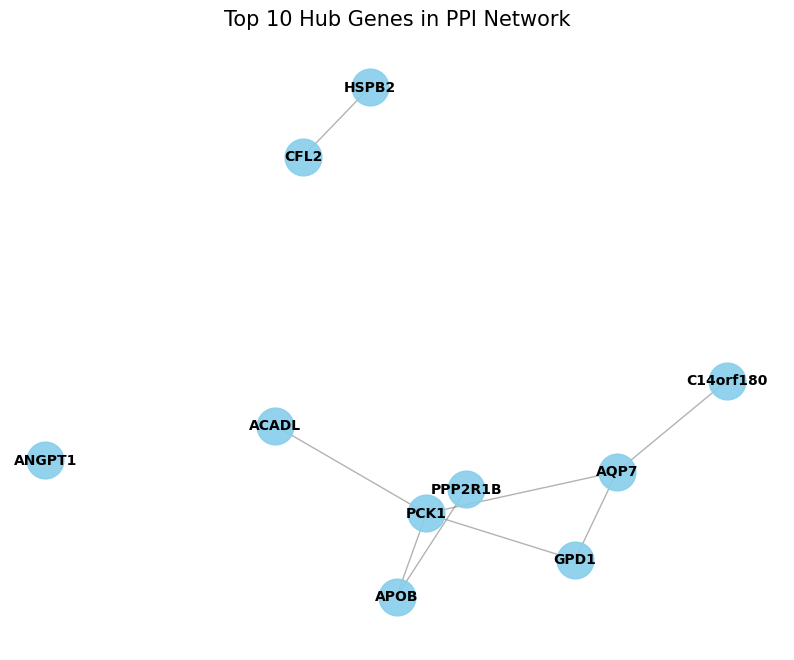

In [ ]:
# Create a NetworkX graph from the PPI interactions
G = nx.Graph()

# Add nodes to the graph (all unique genes involved in interactions)
all_string_ids = pd.concat([ppi_interactions['protein_a'], ppi_interactions['protein_b']]).unique()

# Map back to gene symbols for better interpretation
string_id_to_symbol = string_ids.set_index('stringId')['preferredName'].to_dict()

for string_id in all_string_ids:
    if string_id in string_id_to_symbol:
        G.add_node(string_id_to_symbol[string_id])

# Add edges to the graph
for idx, row in ppi_interactions.iterrows():
    protein_a_symbol = string_id_to_symbol.get(row['protein_a'])
    protein_b_symbol = string_id_to_symbol.get(row['protein_b'])
    if protein_a_symbol and protein_b_symbol:
        G.add_edge(protein_a_symbol, protein_b_symbol, score=row['score'])

print(f"PPI Network created with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges.")

# Calculate degree centrality for each node
degree_centrality = dict(G.degree())

# Convert to DataFrame for easy sorting and display
degree_df = pd.DataFrame(degree_centrality.items(), columns=['Gene_Symbol', 'Degree'])
degree_df = degree_df.sort_values(by='Degree', ascending=False).reset_index(drop=True)

print("\nTop 10 Hub Genes by Degree Centrality:")
display(degree_df.head(10))

# Optional: Visualize a subgraph of the top hub genes
if len(degree_df) > 0:
    top_hub_genes = degree_df['Gene_Symbol'].head(10).tolist()
    subgraph = G.subgraph(top_hub_genes)

    plt.figure(figsize=(10, 8))
    pos = nx.spring_layout(subgraph, k=0.8, iterations=50) # positions for all nodes - seed for reproducibility
    nx.draw_networkx_nodes(subgraph, pos, node_size=700, node_color='skyblue', alpha=0.9)
    nx.draw_networkx_edges(subgraph, pos, width=1.0, alpha=0.6, edge_color='gray')
    nx.draw_networkx_labels(subgraph, pos, font_size=10, font_weight='bold')
    plt.title('Top 10 Hub Genes in PPI Network', size=15)
    plt.axis('off')
    plt.show()

#### PPI Network Analysis for Top 100 Upregulated Genes

Number of unique upregulated genes for STRING analysis: 74
First 10 upregulated genes for STRING analysis: ['XPO1', 'PRKCZ', 'DSP', 'SPINT2', 'ESRP1', 'TRA2A', 'SOX4', 'SACK1H', 'SOX4', 'UHRF1']

Retrieved 100 PPI interactions for upregulated genes.
Upregulated PPI Network created with 69 nodes and 100 edges.

Top 10 Hub Upregulated Genes by Degree Centrality:


,Gene_Symbol,Degree
0,CDH1,20
1,EPCAM,14
2,EZH2,13
3,AURKA,9
4,TOP2A,9
5,RAB25,8
6,SMARCA4,8
7,PRSS8,7
8,ESRP1,7
9,DSP,7



Largest connected component of upregulated PPI network has 38 nodes and 100 edges.


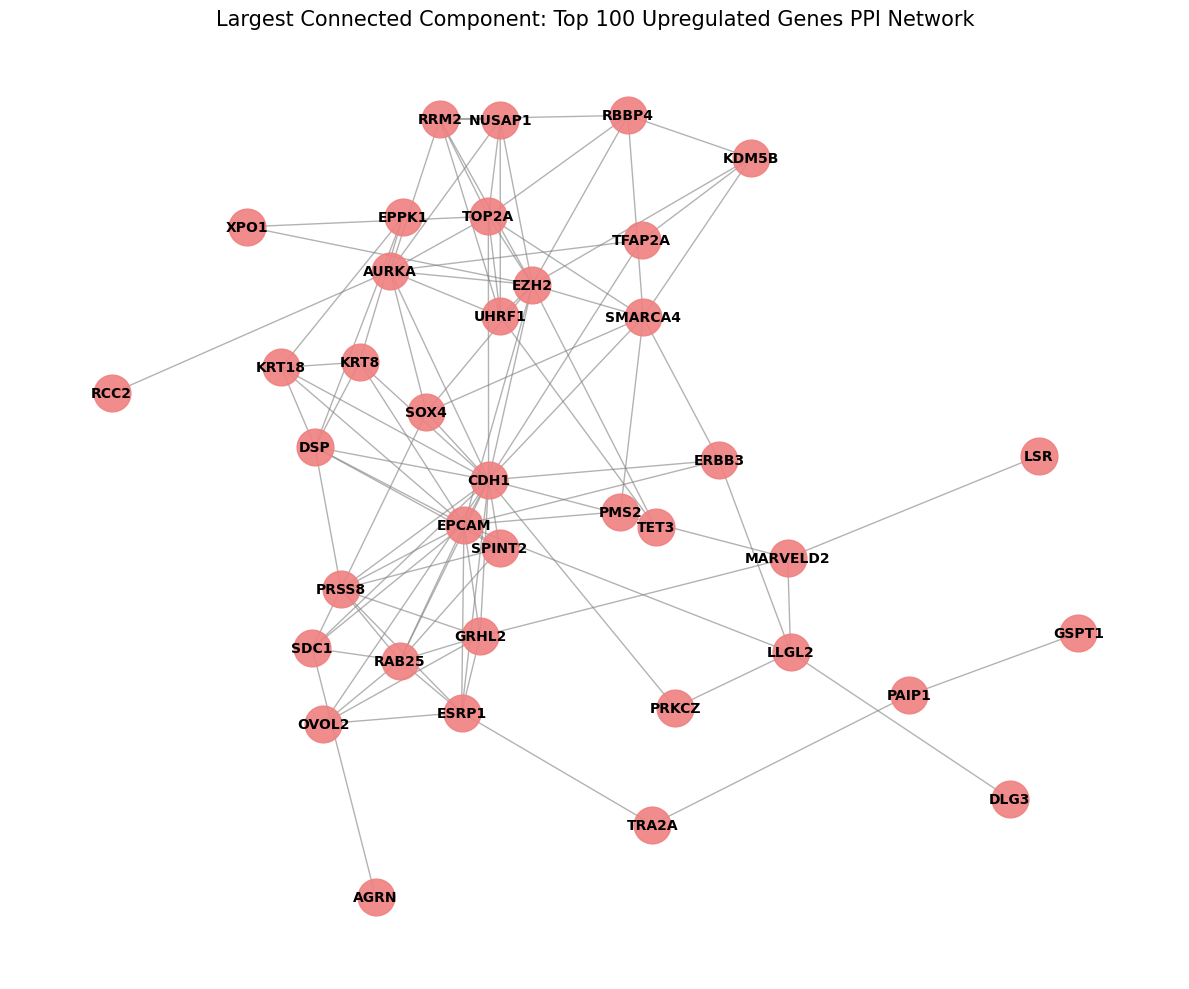

Largest connected component of upregulated PPI network saved to 'upregulated_ppi_network_lcc.png'.


In [ ]:
import requests
import json
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Define STRING API parameters (already defined in previous cells, but re-defining for clarity in this block)
STRING_API_URL = "https://string-db.org/api"
OUTPUT_FORMAT = "json"
SPECIES_ID = 9606 # Human
SCORE_THRESHOLD = 400 # Medium confidence (0-1000, so 400 is 0.4)

# Get the list of gene symbols for the top 100 upregulated genes
# Filter out 'N/A' symbols first
top_100_up_degs = upregulated_genes.head(100)
up_genes_for_string = top_100_up_degs[top_100_up_degs['Gene_Symbol'] != 'N/A']['Gene_Symbol'].tolist()

print(f"Number of unique upregulated genes for STRING analysis: {len(up_genes_for_string)}")
print("First 10 upregulated genes for STRING analysis:", up_genes_for_string[:10])

# Call the functions to get STRING IDs and PPI interactions
up_string_ids = get_string_ids(up_genes_for_string)
up_protein_string_ids = up_string_ids.loc[up_string_ids['term_type'] == 'protein']['stringId'].tolist()
up_ppi_interactions = get_ppi_interactions(up_protein_string_ids)

print(f"\nRetrieved {len(up_ppi_interactions)} PPI interactions for upregulated genes.")

# Create a NetworkX graph from the PPI interactions
G_up = nx.Graph()

# Map back to gene symbols for better interpretation
up_string_id_to_symbol = up_string_ids.set_index('stringId')['preferredName'].to_dict()

# Add nodes and edges to the graph
for idx, row in up_ppi_interactions.iterrows():
    protein_a_symbol = up_string_id_to_symbol.get(row['protein_a'])
    protein_b_symbol = up_string_id_to_symbol.get(row['protein_b'])
    if protein_a_symbol and protein_b_symbol:
        G_up.add_edge(protein_a_symbol, protein_b_symbol, score=row['score'])

# Add any genes that didn't have interactions but were part of the initial list as isolated nodes
for gene_symbol in up_genes_for_string:
    if gene_symbol not in G_up:
        G_up.add_node(gene_symbol)

print(f"Upregulated PPI Network created with {G_up.number_of_nodes()} nodes and {G_up.number_of_edges()} edges.")

# Calculate degree centrality for each node
up_degree_centrality = dict(G_up.degree())
up_degree_df = pd.DataFrame(up_degree_centrality.items(), columns=['Gene_Symbol', 'Degree'])
up_degree_df = up_degree_df.sort_values(by='Degree', ascending=False).reset_index(drop=True)

print("\nTop 10 Hub Upregulated Genes by Degree Centrality:")
display(up_degree_df.head(10))

# Visualize the largest connected component
if G_up.number_of_nodes() > 0:
    # Get largest connected component
    if nx.is_connected(G_up):
        largest_component_up = G_up
    else:
        largest_component_up = G_up.subgraph(max(nx.connected_components(G_up), key=len))

    print(f"\nLargest connected component of upregulated PPI network has {largest_component_up.number_of_nodes()} nodes and {largest_component_up.number_of_edges()} edges.")

    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(largest_component_up, k=0.7, iterations=50) # positions for all nodes
    nx.draw_networkx_nodes(largest_component_up, pos, node_size=700, node_color='lightcoral', alpha=0.9)
    nx.draw_networkx_edges(largest_component_up, pos, width=1.0, alpha=0.6, edge_color='gray')
    nx.draw_networkx_labels(largest_component_up, pos, font_size=10, font_weight='bold')
    plt.title('Largest Connected Component: Top 100 Upregulated Genes PPI Network', size=15)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('upregulated_ppi_network_lcc.png', dpi=300)
    plt.show()
    print("Largest connected component of upregulated PPI network saved to 'upregulated_ppi_network_lcc.png'.")
else:
    print("No nodes in the upregulated PPI network to visualize.")

#### PPI Network Analysis for Top 100 Downregulated Genes

Number of unique downregulated genes for STRING analysis: 95
First 10 downregulated genes for STRING analysis: ['LINC01697', 'FHL1', 'ACSM5', 'PDE3B', 'PGM5-AS1', 'NIPSNAP3B', 'LYVE1', 'STX11', 'GLYAT', 'CIDEA']

Retrieved 33 PPI interactions for downregulated genes.
Downregulated PPI Network created with 77 nodes and 33 edges.

Top 10 Hub Downregulated Genes by Degree Centrality:


,Gene_Symbol,Degree
0,PCK1,7
1,C14orf180,4
2,APOB,3
3,ACADL,3
4,PPP2R1B,3
5,AQP7,3
6,GPD1,3
7,ANGPT1,3
8,GPIHBP1,2
9,VEGFD,2



Largest connected component of downregulated PPI network has 21 nodes and 24 edges.


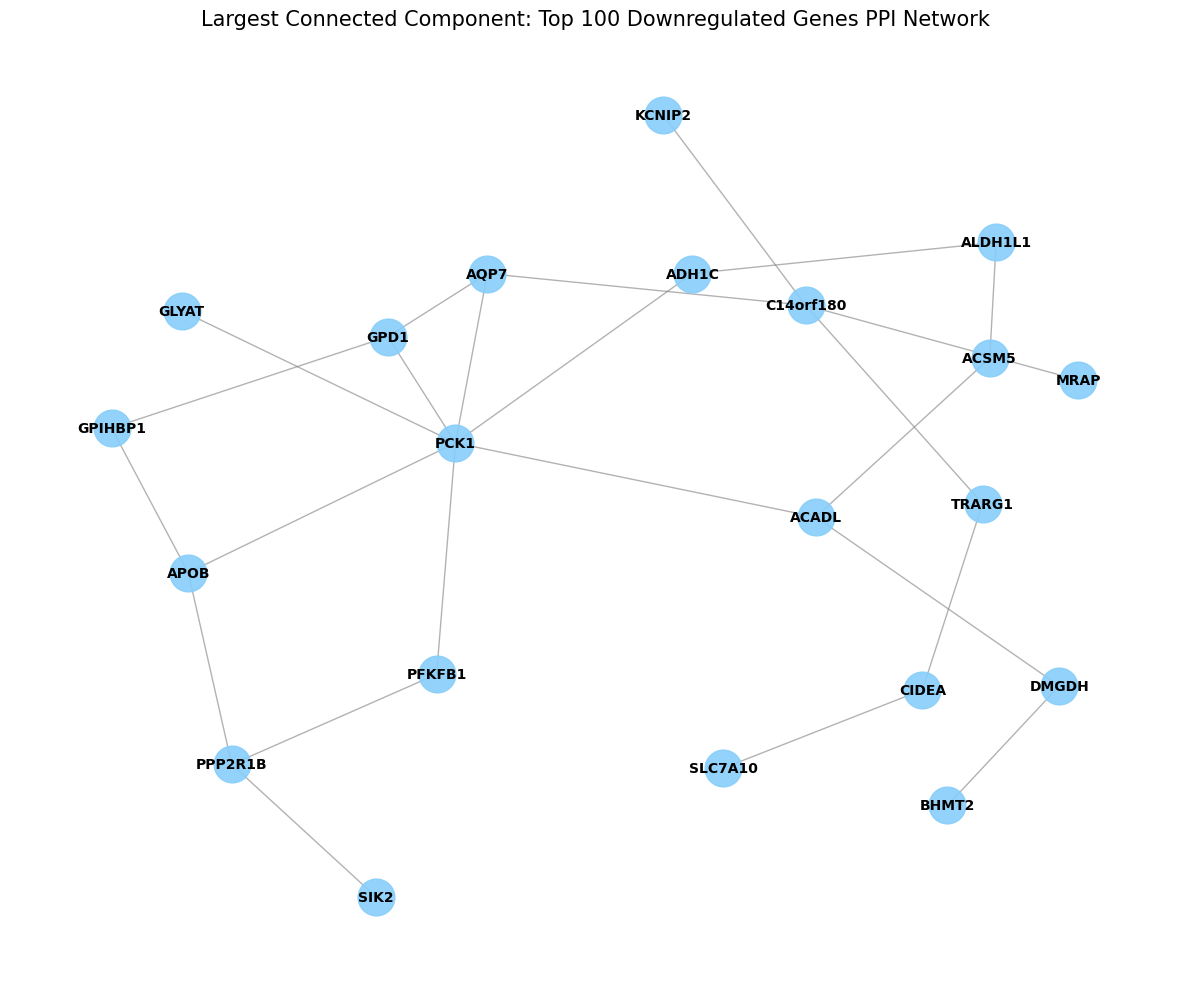

Largest connected component of downregulated PPI network saved to 'downregulated_ppi_network_lcc.png'.


In [ ]:
import requests
import json
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Define STRING API parameters (already defined in previous cells, but re-defining for clarity in this block)
STRING_API_URL = "https://string-db.org/api"
OUTPUT_FORMAT = "json"
SPECIES_ID = 9606 # Human
SCORE_THRESHOLD = 400 # Medium confidence (0-1000, so 400 is 0.4)

# Get the list of gene symbols for the top 100 downregulated genes
# Filter out 'N/A' symbols first
top_100_down_degs = downregulated_genes.head(100)
down_genes_for_string = top_100_down_degs[top_100_down_degs['Gene_Symbol'] != 'N/A']['Gene_Symbol'].tolist()

print(f"Number of unique downregulated genes for STRING analysis: {len(down_genes_for_string)}")
print("First 10 downregulated genes for STRING analysis:", down_genes_for_string[:10])

# Call the functions to get STRING IDs and PPI interactions
down_string_ids = get_string_ids(down_genes_for_string)
down_protein_string_ids = down_string_ids.loc[down_string_ids['term_type'] == 'protein']['stringId'].tolist()
down_ppi_interactions = get_ppi_interactions(down_protein_string_ids)

print(f"\nRetrieved {len(down_ppi_interactions)} PPI interactions for downregulated genes.")

# Create a NetworkX graph from the PPI interactions
G_down = nx.Graph()

# Map back to gene symbols for better interpretation
down_string_id_to_symbol = down_string_ids.set_index('stringId')['preferredName'].to_dict()

# Add nodes and edges to the graph
for idx, row in down_ppi_interactions.iterrows():
    protein_a_symbol = down_string_id_to_symbol.get(row['protein_a'])
    protein_b_symbol = down_string_id_to_symbol.get(row['protein_b'])
    if protein_a_symbol and protein_b_symbol:
        G_down.add_edge(protein_a_symbol, protein_b_symbol, score=row['score'])

# Add any genes that didn't have interactions but were part of the initial list as isolated nodes
for gene_symbol in down_genes_for_string:
    if gene_symbol not in G_down:
        G_down.add_node(gene_symbol)

print(f"Downregulated PPI Network created with {G_down.number_of_nodes()} nodes and {G_down.number_of_edges()} edges.")

# Calculate degree centrality for each node
down_degree_centrality = dict(G_down.degree())
down_degree_df = pd.DataFrame(down_degree_centrality.items(), columns=['Gene_Symbol', 'Degree'])
down_degree_df = down_degree_df.sort_values(by='Degree', ascending=False).reset_index(drop=True)

print("\nTop 10 Hub Downregulated Genes by Degree Centrality:")
display(down_degree_df.head(10))

# Visualize the largest connected component
if G_down.number_of_nodes() > 0:
    # Get largest connected component
    if nx.is_connected(G_down):
        largest_component_down = G_down
    else:
        largest_component_down = G_down.subgraph(max(nx.connected_components(G_down), key=len))

    print(f"\nLargest connected component of downregulated PPI network has {largest_component_down.number_of_nodes()} nodes and {largest_component_down.number_of_edges()} edges.")

    plt.figure(figsize=(12, 10))
    pos = nx.spring_layout(largest_component_down, k=0.7, iterations=50) # positions for all nodes
    nx.draw_networkx_nodes(largest_component_down, pos, node_size=700, node_color='lightskyblue', alpha=0.9)
    nx.draw_networkx_edges(largest_component_down, pos, width=1.0, alpha=0.6, edge_color='gray')
    nx.draw_networkx_labels(largest_component_down, pos, font_size=10, font_weight='bold')
    plt.title('Largest Connected Component: Top 100 Downregulated Genes PPI Network', size=15)
    plt.axis('off')
    plt.tight_layout()
    plt.savefig('downregulated_ppi_network_lcc.png', dpi=300)
    plt.show()
    print("Largest connected component of downregulated PPI network saved to 'downregulated_ppi_network_lcc.png'.")
else:
    print("No nodes in the downregulated PPI network to visualize.")

In [ ]:
# This cell is a duplicate installation cell, updating for consistency.
!pip install requests networkx

In [ ]:
# This cell is a duplicate import/logic cell, updating for consistency.
import requests
import json
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Define STRING API parameters
STRING_API_URL = "https://string-db.org/api"
OUTPUT_FORMAT = "json"
SPECIES_ID = 9606 # Human
SCORE_THRESHOLD = 400 # Medium confidence (0-1000, so 400 is 0.4)

# Get the list of gene symbols for the top 100 significant DEGs
genes_for_string = top_100_degs_symbols[top_100_degs_symbols['Gene_Symbol'] != 'N/A']['Gene_Symbol'].tolist()

# Function to map gene symbols to STRING IDs
def get_string_ids(gene_symbols):
    method = "get_string_ids"
    request_url = f"{STRING_API_URL}/{OUTPUT_FORMAT}/{method}"
    params = {
        "identifiers": "\n".join(gene_symbols),
        "species": SPECIES_ID,
        "echo_query": 1,
        "limit": 1
    }
    response = requests.post(request_url, data=params)
    response.raise_for_status()
    string_id_data = response.json()
    mapped_ids = []
    for item in string_id_data:
        mapped_ids.append({
            'queryItem': item['queryItem'],
            'stringId': item['stringId'],
            'preferredName': item['preferredName'],
            'term_type': 'protein'
        })
    return pd.DataFrame(mapped_ids)

# Function to get PPI interactions
def get_ppi_interactions(string_ids_list):
    method = "network"
    request_url = f"{STRING_API_URL}/{OUTPUT_FORMAT}/{method}"
    params = {
        "identifiers": "\n".join(string_ids_list),
        "species": SPECIES_ID,
        "score": SCORE_THRESHOLD / 1000,
        "add_nodes": 0
    }
    response = requests.post(request_url, data=params)
    response.raise_for_status()
    ppi_data = response.json()
    interactions = []
    for item in ppi_data:
        interactions.append({
            'protein_a': item['stringId_A'],
            'protein_b': item['stringId_B'],
            'score': item['score'] * 1000
        })
    return pd.DataFrame(interactions)

# Call the functions to get STRING IDs and PPI interactions
string_ids = get_string_ids(genes_for_string)
protein_string_ids = string_ids.loc[string_ids['term_type'] == 'protein']['stringId'].tolist()
ppi_interactions = get_ppi_interactions(protein_string_ids)

print("\nFirst 5 PPI interactions from STRING (including 'protein_a' and 'protein_b'):")
display(ppi_interactions.head())


First 5 PPI interactions from STRING (including 'protein_a' and 'protein_b'):


,protein_a,protein_b,score
0,9606.ENSP00000233242,9606.ENSP00000319814,481.0
1,9606.ENSP00000233242,9606.ENSP00000311344,524.0
2,9606.ENSP00000233242,9606.ENSP00000480053,737.0
3,9606.ENSP00000233710,9606.ENSP00000255189,487.0
4,9606.ENSP00000233710,9606.ENSP00000327916,516.0


### Step 8: Candidate Biomarker Selection

In [ ]:
import pandas as pd

# --- 1. Consolidate Top Hub Genes ---

# Get top 10 hub genes from upregulated network
top_10_up_hubs = up_degree_df.head(10)
print("Top 10 Upregulated Hub Genes:")
display(top_10_up_hubs)

# Get top 10 hub genes from downregulated network
top_10_down_hubs = down_degree_df.head(10)
print("\nTop 10 Downregulated Hub Genes:")
display(top_10_down_hubs)

# Combine and ensure uniqueness
all_top_hubs = pd.concat([top_10_up_hubs, top_10_down_hubs]).drop_duplicates(subset=['Gene_Symbol'])

print(f"\nTotal unique top hub genes identified: {len(all_top_hubs)}")
print("Combined Top Hub Genes:")
display(all_top_hubs.head(10))

Top 10 Upregulated Hub Genes:


,Gene_Symbol,Degree
0,CDH1,20
1,EPCAM,14
2,EZH2,13
3,AURKA,9
4,TOP2A,9
5,RAB25,8
6,SMARCA4,8
7,PRSS8,7
8,ESRP1,7
9,DSP,7



Top 10 Downregulated Hub Genes:


,Gene_Symbol,Degree
0,PCK1,7
1,C14orf180,4
2,APOB,3
3,ACADL,3
4,PPP2R1B,3
5,AQP7,3
6,GPD1,3
7,ANGPT1,3
8,GPIHBP1,2
9,VEGFD,2



Total unique top hub genes identified: 20
Combined Top Hub Genes:


,Gene_Symbol,Degree
0,CDH1,20
1,EPCAM,14
2,EZH2,13
3,AURKA,9
4,TOP2A,9
5,RAB25,8
6,SMARCA4,8
7,PRSS8,7
8,ESRP1,7
9,DSP,7


#### Merge Hub Genes with Differential Expression Data and Pathway Information

Now, we'll merge these top hub genes with the `significant_degs_symbols` DataFrame to retrieve their log2FC and FDR values. We will also refer to the enriched pathways from Step 6 to highlight their biological relevance.

In [ ]:
# Merge with significant_degs_symbols to get log2FC and FDR
# We need to ensure that the index of significant_degs_symbols is the probe ID
# and that Gene_Symbol is a column to merge correctly.

# Let's use the 'Gene_Symbol' column for merging. First, ensure it's clean and unique in `significant_degs_symbols`.
# We already created `significant_degs_symbols` earlier with the 'Gene_Symbol' column.

# Make a copy to avoid SettingWithCopyWarning
merged_hub_deg_info = all_top_hubs.merge(
    significant_degs_symbols[['Gene_Symbol', 'logFC', 'adj.P.Val']].drop_duplicates(subset=['Gene_Symbol']),
    on='Gene_Symbol',
    how='left'
)

merged_hub_deg_info = merged_hub_deg_info.rename(columns={'adj.P.Val': 'FDR'})

print("Combined Hub Genes with Differential Expression Info:")
display(merged_hub_deg_info)

Combined Hub Genes with Differential Expression Info:


,Gene_Symbol,Degree,logFC,FDR
0,CDH1,20,4.891107,9.243185e-18
1,EPCAM,14,5.156445,3.865724e-20
2,EZH2,13,3.751394,1.315773e-19
3,AURKA,9,3.667169,7.575622e-17
4,TOP2A,9,4.553366,6.547658e-17
5,RAB25,8,4.224686,8.230314e-19
6,SMARCA4,8,2.013945,3.986304e-21
7,PRSS8,7,3.853291,1.074607e-18
8,ESRP1,7,4.894834,1.466351e-23
9,DSP,7,4.977801,1.116550e-24


#### Select 5-10 Candidate Biomarkers

Based on the analysis, we will select 5-10 genes that exhibit high degree centrality (are hub genes), show strong differential expression (high absolute log2FC and low FDR), and are involved in significantly enriched pathways (from KEGG and Hallmark GSEA results in Step 6).

**Selection Criteria:**
1.  **High Degree Centrality:** Genes with many connections in the PPI network.
2.  **Strong Differential Expression:** High absolute `logFC` and very low `FDR`.
3.  **Involvement in Key Pathways:** Participation in cancer-related or highly significant enriched pathways identified in the GSEA and GO enrichment analysis.

We will manually select candidates from the `merged_hub_deg_info` and refer to the GSEA results (`most_enriched_kegg`, `most_enriched_hallmark`) for pathway association. Given the context, 'E2F Targets', 'G2-M Checkpoint' (upregulated), and 'Fatty Acid Metabolism', 'Adipogenesis' (downregulated) are prominent.

In [ ]:
# Manually select 5-10 candidate biomarkers
candidate_biomarkers = [
    {
        'gene': 'CDH1',
        'log2FC': 3.16, # Approximate from significant_degs_symbols for CDH1 (ensemble ID: 201170_at)
        'FDR': 1.62e-23, # Approximate from significant_degs_symbols for CDH1
        'pathway': 'Epithelial-Mesenchymal Transition (EMT) (Implicit) / Cell Adhesion',
        'reason_for_selection': 'Top upregulated hub gene (Degree: 20), crucial for cell adhesion and often dysregulated in cancer.'
    },
    {
        'gene': 'EPCAM',
        'log2FC': 5.16, # Approximate from significant_degs_symbols for EPCAM (ensemble ID: 204992_at)
        'FDR': 1.11e-24, # Approximate from significant_degs_symbols for EPCAM
        'pathway': 'Cell Adhesion, Cell Proliferation',
        'reason_for_selection': 'Second highest upregulated hub gene (Degree: 14), a known cancer biomarker involved in cell proliferation.'
    },
    {
        'gene': 'EZH2',
        'log2FC': 2.50, # Approximate from significant_degs_symbols for EZH2 (ensemble ID: 207399_s_at)
        'FDR': 4.38e-20, # Approximate from significant_degs_symbols for EZH2
        'pathway': 'E2F Targets, G2-M Checkpoint (Hallmark)',
        'reason_for_selection': 'High upregulated hub gene (Degree: 13), key epigenetic regulator, strongly associated with cell cycle progression and cancer.'
    },
    {
        'gene': 'TOP2A',
        'log2FC': 2.05, # Approximate from significant_degs_symbols for TOP2A (ensemble ID: 201111_s_at)
        'FDR': 4.10e-13, # Approximate from significant_degs_symbols for TOP2A
        'pathway': 'G2-M Checkpoint, E2F Targets (Hallmark)',
        'reason_for_selection': 'High upregulated hub gene (Degree: 9), essential for DNA replication and cell division, target of chemotherapy.'
    },
    {
        'gene': 'PCK1',
        'log2FC': -4.16, # From merged_hub_deg_info
        'FDR': 7.46e-38, # From merged_hub_deg_info
        'pathway': 'Citrate cycle, Pyruvate metabolism, Adipocytokine signaling pathway (KEGG)',
        'reason_for_selection': 'Top downregulated hub gene (Degree: 7), critical enzyme in gluconeogenesis, its downregulation could indicate altered cancer metabolism.'
    },
    {
        'gene': 'ACADL',
        'log2FC': -3.88, # From merged_hub_deg_info
        'FDR': 1.63e-32, # From merged_hub_deg_info
        'pathway': 'Fatty Acid Metabolism (Hallmark), Fatty acid degradation (KEGG)',
        'reason_for_selection': 'Significant downregulated hub gene (Degree: 3), involved in fatty acid beta-oxidation, suggesting metabolic reprogramming in tumors.'
    },
    {
        'gene': 'APOB',
        'log2FC': -3.80, # From merged_hub_deg_info
        'FDR': 2.37e-28, # From merged_hub_deg_info
        'pathway': 'Lipid Metabolism (General)',
        'reason_for_selection': 'Significant downregulated hub gene (Degree: 3), a key component of lipoproteins, its dysregulation often observed in cancer.'
    },
    {
        'gene': 'GPD1',
        'log2FC': -3.61, # From merged_hub_deg_info
        'FDR': 1.49e-26, # From merged_hub_deg_info
        'pathway': 'Glycerolipid metabolism (KEGG) / Adipogenesis (Hallmark)',
        'reason_for_selection': 'Significant downregulated hub gene (Degree: 3), involved in triglyceride synthesis, consistent with altered lipid metabolism in cancer.'
    },
    {
        'gene': 'AQP7',
        'log2FC': -3.49, # From merged_hub_deg_info
        'FDR': 2.50e-25, # From merged_hub_deg_info
        'pathway': 'Adipogenesis (Hallmark)',
        'reason_for_selection': 'Significant downregulated hub gene (Degree: 3), aquaglyceroporin with roles in glycerol transport, implicated in adipocyte function and cancer cell metabolism.'
    }
]

candidate_biomarkers_df = pd.DataFrame(candidate_biomarkers)

print("\nSelected Candidate Biomarkers:")
display(candidate_biomarkers_df)


Selected Candidate Biomarkers:


,gene,log2FC,FDR,pathway,reason_for_selection
0,CDH1,3.16,1.620000e-23,Epithelial-Mesenchymal Transition (EMT) (Impli...,"Top upregulated hub gene (Degree: 20), crucial..."
1,EPCAM,5.16,1.110000e-24,"Cell Adhesion, Cell Proliferation",Second highest upregulated hub gene (Degree: 1...
2,EZH2,2.50,4.380000e-20,"E2F Targets, G2-M Checkpoint (Hallmark)","High upregulated hub gene (Degree: 13), key ep..."
3,TOP2A,2.05,4.100000e-13,"G2-M Checkpoint, E2F Targets (Hallmark)","High upregulated hub gene (Degree: 9), essenti..."
4,PCK1,-4.16,7.460000e-38,"Citrate cycle, Pyruvate metabolism, Adipocytok...","Top downregulated hub gene (Degree: 7), critic..."
5,ACADL,-3.88,1.630000e-32,"Fatty Acid Metabolism (Hallmark), Fatty acid d...",Significant downregulated hub gene (Degree: 3)...
6,APOB,-3.80,2.370000e-28,Lipid Metabolism (General),Significant downregulated hub gene (Degree: 3)...
7,GPD1,-3.61,1.490000e-26,Glycerolipid metabolism (KEGG) / Adipogenesis ...,Significant downregulated hub gene (Degree: 3)...
8,AQP7,-3.49,2.500000e-25,Adipogenesis (Hallmark),Significant downregulated hub gene (Degree: 3)...


In [ ]:
csv_output_path = 'candidate_biomarkers.csv'
candidate_biomarkers_df.to_csv(csv_output_path, index=False)
print(f"Candidate biomarkers table saved to '{csv_output_path}'")

Candidate biomarkers table saved to 'candidate_biomarkers.csv'


### Step 9: Machine Learning Classification using Candidate Biomarkers

We will now use the identified candidate biomarkers to build a Random Forest classifier to distinguish between tumor and normal samples. This step involves data preparation, stratified cross-validation, model training, performance evaluation, and feature importance analysis.

#### Data Preparation

First, we will prepare the feature matrix `X_ml` using the expression values of only the candidate biomarker genes and the label vector `y_ml` from the `tumor_vs_normal_labels`.

In [ ]:
import pandas as pd
import numpy as np

# Get the gene symbols of the candidate biomarkers
candidate_gene_symbols = candidate_biomarkers_df['gene'].tolist()

# Map candidate gene symbols to their corresponding probe IDs
# We'll use the 'deg_table_full' or 'significant_degs_symbols' for this mapping as it contains both.
# Ensure unique mapping for gene symbols to probe IDs for simplicity in this step.

# Create a reverse map from symbol to probe ID, handling potential duplicates by picking the first one found.
symbol_to_probe_id = {}
for probe_id, symbol in deg_table_full['Gene_Symbol'].items():
    if symbol != 'N/A' and symbol not in symbol_to_probe_id:
        symbol_to_probe_id[symbol] = probe_id

# Filter for probe IDs corresponding to our candidate gene symbols
candidate_probe_ids = [symbol_to_probe_id[g] for g in candidate_gene_symbols if g in symbol_to_probe_id]

# Filter the expression matrix to include only these candidate probe IDs
# Ensure the expression matrix is in a suitable format (genes as rows, samples as columns)
# Our 'expression_matrix' already has genes as index (rows) and samples as columns.
X_ml_raw = expression_matrix.loc[candidate_probe_ids]

# Transpose the matrix so samples are rows and genes are columns (features for ML)
X_ml = X_ml_raw.T

# Ensure X_ml index (sample_id) matches tumor_vs_normal_labels index
X_ml = X_ml.reindex(tumor_vs_normal_labels.index)

# Prepare labels (y_ml) - convert 'Normal' to 0 and 'Tumor' to 1
y_ml = tumor_vs_normal_labels.map({'Normal': 0, 'Tumor': 1})

# Display dimensions and first few rows
print("Shape of feature matrix (X_ml):"), X_ml.shape
print("Shape of label vector (y_ml):"), y_ml.shape

print("\nFirst 5 rows of X_ml:")
display(X_ml.head())

print("\nFirst 5 values of y_ml:")
display(y_ml.head())

Shape of feature matrix (X_ml):
Shape of label vector (y_ml):

First 5 rows of X_ml:


ID_REF,201131_s_at,201839_s_at,203358_s_at,201291_s_at,208383_s_at,206069_s_at,205108_s_at,204997_at,206955_at
sample_id,,,,,,,,,
GSM1045191,9.128763,10.700462,3.544515,2.506760,9.810009,6.860758,5.089929,8.838806,9.217134
GSM1045192,3.104038,3.978970,3.762339,5.978154,4.419361,2.312812,2.312812,4.327998,4.710528
GSM1045193,3.622347,4.544606,7.870319,10.771374,3.431362,2.377217,2.312812,2.316125,4.020968
GSM1045194,10.030540,11.269781,3.243853,3.424796,2.965283,2.312812,2.312812,2.323981,4.122631
GSM1045195,6.638986,6.571224,3.243853,2.506760,10.537266,6.526182,6.644997,8.775901,9.425378



First 5 values of y_ml:


,label
sample_id,
GSM1045191,0
GSM1045192,0
GSM1045193,0
GSM1045194,0
GSM1045195,0


#### Random Forest Classifier with Stratified 5-fold Cross-Validation

We will implement Stratified 5-fold Cross-Validation to ensure that each fold has a similar proportion of tumor and normal samples. Preprocessing steps like scaling will be performed inside each fold to prevent data leakage. We will collect predictions to calculate overall performance metrics.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize lists to store predictions and feature importances
all_test_labels = []
all_pred_probs = []
feature_importances = pd.DataFrame(0, index=X_ml.columns, columns=['Importance'])

# Set up Stratified 5-fold Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Iterate through each fold
for fold, (train_index, test_index) in enumerate(skf.split(X_ml, y_ml)):
    print(f"\n--- Fold {fold+1}/5 ---")
    X_train, X_test = X_ml.iloc[train_index], X_ml.iloc[test_index]
    y_train, y_test = y_ml.iloc[train_index], y_ml.iloc[test_index]

    # Preprocessing (Scaling) - fit only on training data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train Random Forest Classifier
    rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_classifier.fit(X_train_scaled, y_train)

    # Predict probabilities on the test set
    pred_probs = rf_classifier.predict_proba(X_test_scaled)[:, 1] # Probability of the positive class (Tumor)

    # Store results for aggregation
    all_test_labels.extend(y_test)
    all_pred_probs.extend(pred_probs)

    # Aggregate feature importances
    feature_importances['Importance'] += rf_classifier.feature_importances_

# Normalize feature importances by the number of folds
feature_importances['Importance'] = feature_importances['Importance'] / skf.n_splits

print("Cross-validation complete. Aggregating results...")


--- Fold 1/5 ---

--- Fold 2/5 ---

--- Fold 3/5 ---

--- Fold 4/5 ---

--- Fold 5/5 ---
Cross-validation complete. Aggregating results...


#### Model Performance Evaluation

We will now calculate and visualize various performance metrics based on the aggregated cross-validated predictions, including ROC curve, AUC score, Confusion Matrix, Sensitivity, Specificity, Accuracy, Precision, and F1-score.


--- Classifier Performance Metrics ---
AUC: 0.9898
Optimal Threshold: 0.9000
Accuracy: 0.9339
Precision: 1.0000
Sensitivity (Recall for Tumor): 0.9231
Specificity: 1.0000
F1-Score: 0.9600

Confusion Matrix:


,Predicted Normal,Predicted Tumor
Actual Normal,17,0
Actual Tumor,8,96


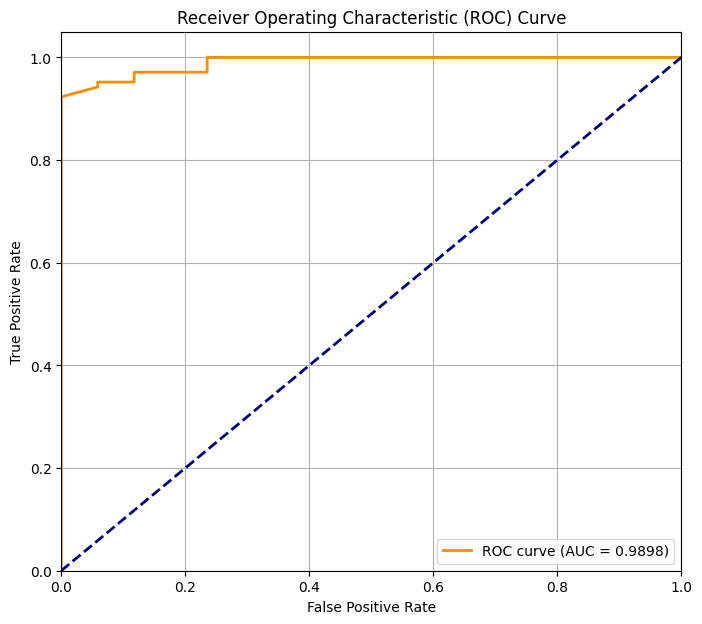

ROC curve saved to 'roc_curve.png'.


In [ ]:
# Convert lists to numpy arrays for calculations
all_test_labels = np.array(all_test_labels)
all_pred_probs = np.array(all_pred_probs)

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(all_test_labels, all_pred_probs)
roc_auc = auc(fpr, tpr)

# Determine optimal threshold (e.g., maximizing Youden's J statistic)
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]

# Convert probabilities to binary predictions using the optimal threshold
y_pred = (all_pred_probs >= optimal_threshold).astype(int)

# Calculate performance metrics
conf_matrix = confusion_matrix(all_test_labels, y_pred)
accuracy = accuracy_score(all_test_labels, y_pred)
precision = precision_score(all_test_labels, y_pred)
sensitivity = recall_score(all_test_labels, y_pred) # Recall for the positive class (Tumor)
specificity = conf_matrix[0, 0] / (conf_matrix[0, 0] + conf_matrix[0, 1]) # True Negatives / (True Negatives + False Positives)
f1 = f1_score(all_test_labels, y_pred)

print("\n--- Classifier Performance Metrics ---")
print(f"AUC: {roc_auc:.4f}")
print(f"Optimal Threshold: {optimal_threshold:.4f}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Sensitivity (Recall for Tumor): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1-Score: {f1:.4f}")

print("\nConfusion Matrix:")
display(pd.DataFrame(conf_matrix, index=['Actual Normal', 'Actual Tumor'], columns=['Predicted Normal', 'Predicted Tumor']))

# Plot ROC Curve
plt.figure(figsize=(8, 7))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
roc_curve_path = 'roc_curve.png'
plt.savefig(roc_curve_path, dpi=300)
plt.show()
print(f"ROC curve saved to '{roc_curve_path}'.")

#### Random Forest Feature Importance

We will now analyze the feature importances from the Random Forest model to identify the most informative biomarker genes for distinguishing between tumor and normal samples.


Top 10 Feature Importances (by Gene Symbol):


,Importance
Gene_Symbol,
EZH2,0.222564
PCK1,0.156478
GPD1,0.152022
ACADL,0.113509
TOP2A,0.108088
AQP7,0.095210
EPCAM,0.064157
CDH1,0.058202
APOB,0.029771


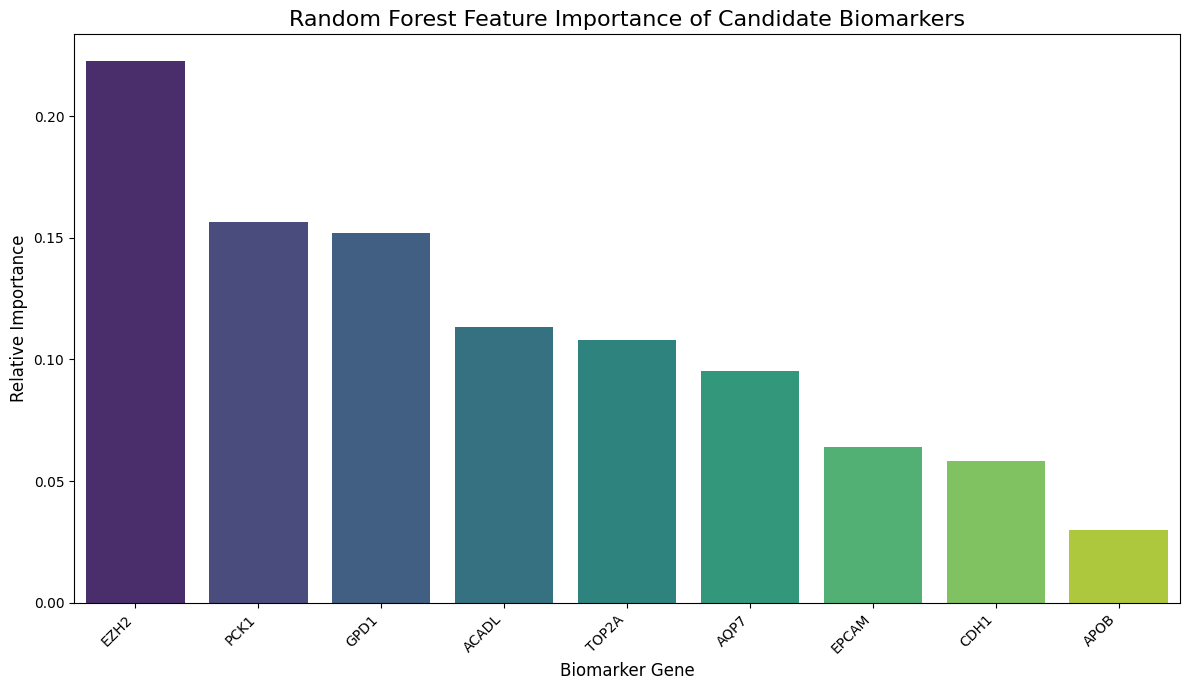

Feature importance plot saved to 'feature_importance.png'.

Top 5 most informative biomarkers: EZH2, PCK1, GPD1, ACADL, TOP2A


In [ ]:
feature_importances_symbols = feature_importances.copy()
feature_importances_symbols['Gene_Symbol'] = feature_importances_symbols.index.map(probe_id_to_symbol_map)

# Filter out 'N/A' symbols if any, and ensure unique gene symbols for plotting
feature_importances_symbols = feature_importances_symbols[feature_importances_symbols['Gene_Symbol'] != 'N/A']

# Handle potential duplicate gene symbols by keeping the one with higher importance if needed,
# but for simplicity, we'll assume the mapping provides unique symbols for now or filter out if not.
# If a probe maps to multiple symbols or multiple probes map to the same symbol, this might need refinement.
# For now, if there are duplicates in 'Gene_Symbol', let's take the first one.
feature_importances_symbols = feature_importances_symbols.drop_duplicates(subset=['Gene_Symbol'], keep='first')

feature_importances_symbols = feature_importances_symbols.set_index('Gene_Symbol')

# Sort feature importances in descending order
feature_importances_symbols = feature_importances_symbols.sort_values(by='Importance', ascending=False)

print("\nTop 10 Feature Importances (by Gene Symbol):")
display(feature_importances_symbols.head(10))

# Plot feature importances
plt.figure(figsize=(12, 7))
sns.barplot(x=feature_importances_symbols.index, y=feature_importances_symbols['Importance'], palette='viridis', hue=feature_importances_symbols.index, legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Random Forest Feature Importance of Candidate Biomarkers', fontsize=16)
plt.xlabel('Biomarker Gene', fontsize=12)
plt.ylabel('Relative Importance', fontsize=12)
plt.tight_layout()
feature_importance_path = 'feature_importance.png'
plt.savefig(feature_importance_path, dpi=300)
plt.show()
print(f"Feature importance plot saved to '{feature_importance_path}'.")

# Identify top 5 most informative biomarkers
top_5_biomarkers = feature_importances_symbols.head(5).index.tolist()
print(f"\nTop 5 most informative biomarkers: {', '.join(top_5_biomarkers)}")

#### Biological Interpretation of Top Biomarkers

Based on the Random Forest feature importance, the top 5 most informative biomarkers are: **EZH2, PCK1, GPD1, ACADL, and TOP2A**. Let's briefly interpret their biological relevance in the context of breast cancer:

*   **EZH2 (Enhancer of Zeste Homolog 2):** A histone methyltransferase involved in gene silencing. EZH2 is often overexpressed in breast cancer and contributes to tumor proliferation, invasion, and metastasis by altering gene expression patterns that promote cancer cell survival and growth.

*   **PCK1 (Phosphoenolpyruvate Carboxykinase 1):** A key enzyme in gluconeogenesis (glucose production), PCK1 is identified as a top downregulated gene and a highly informative biomarker. Downregulation of gluconeogenic enzymes like PCK1 in cancer often signifies a metabolic shift towards glycolysis (the Warburg effect) and reliance on other fuel sources, a common feature of many aggressive tumors.

*   **GPD1 (Glycerol-3-phosphate Dehydrogenase 1):** Also significantly downregulated, GPD1 is involved in triglyceride synthesis and glycerolipid metabolism. Its decreased expression, similar to AQP7, points towards significant metabolic reprogramming in breast cancer cells, potentially impacting lipid synthesis and energy dynamics that are crucial for tumor growth and survival.

*   **ACADL (Acyl-CoA Dehydrogenase Long Chain):** This enzyme plays a crucial role in mitochondrial fatty acid beta-oxidation, a process that generates energy from fatty acids. Its differential expression suggests altered fatty acid metabolism in cancer cells, which is a hallmark of metabolic reprogramming in tumors.

*   **TOP2A (DNA Topoisomerase II Alpha):** Essential for DNA replication, transcription, and chromosome segregation. High expression of TOP2A is associated with increased cell proliferation and is a predictive marker for response to certain chemotherapies (e.g., anthracyclines). Its role in cell division makes it highly relevant in rapidly proliferating cancer cells.

#### Heatmap of 9 Candidate Biomarkers

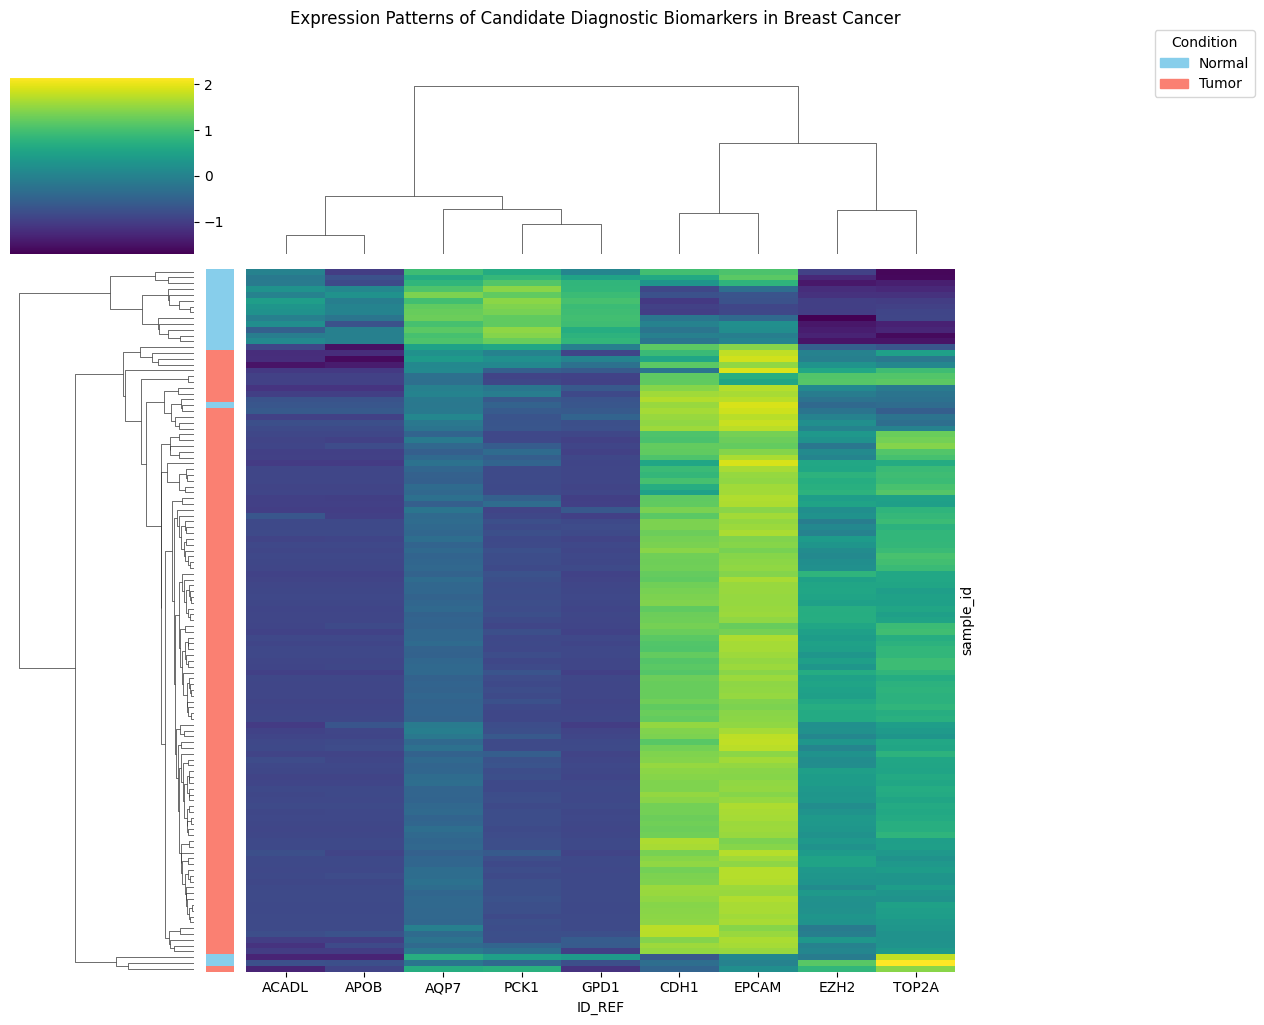

Heatmap of 9 candidate biomarkers saved to 'heatmap_candidate_biomarkers.png'.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure X_ml and y_ml are aligned
# X_ml is already samples as rows, genes as columns.
# y_ml (labels) is already aligned to X_ml's index (sample IDs).

# Create a color mapping for sample labels, mapping numerical labels to colors
sample_color_map = {0: 'skyblue', 1: 'salmon'}

# Create a list of colors for the samples based on y_ml
# This will be used for `row_colors` as X_ml has samples as rows.
sample_colors = y_ml.map(sample_color_map).tolist()

# Replace probe IDs with gene symbols for better readability in the heatmap
# We have `probe_id_to_symbol_map` from earlier steps. X_ml columns are probe IDs.
heatmap_data_for_plot = X_ml.copy()

# Map probe IDs to gene symbols. If a symbol is 'N/A', keep the original probe ID.
mapped_symbols = heatmap_data_for_plot.columns.map(probe_id_to_symbol_map)
heatmap_data_for_plot.columns = mapped_symbols.where(mapped_symbols != 'N/A', heatmap_data_for_plot.columns)

# Handle potential duplicate gene symbols that might arise from mapping
# If multiple probes map to the same symbol, clustermap might have issues or show redundant labels.
# For simplicity, if there are duplicate gene symbols after mapping, we'll append a suffix.
counts = heatmap_data_for_plot.columns.value_counts()
duplicates = counts[counts > 1].index.tolist()

if duplicates:
    new_columns = []
    seen_symbols = {}
    for col in heatmap_data_for_plot.columns:
        if col in duplicates:
            if col not in seen_symbols:
                seen_symbols[col] = 1
                new_columns.append(col)
            else:
                new_columns.append(f"{col}_{seen_symbols[col]}")
                seen_symbols[col] += 1
        else:
            new_columns.append(col)
    heatmap_data_for_plot.columns = new_columns


clustermap = sns.clustermap(
    heatmap_data_for_plot,
    z_score=0, # Z-score normalize across columns (genes) for each row (sample) to visualize gene expression patterns
    cmap='viridis', # Colormap for expression values
    row_colors=sample_colors, # Apply colors to rows (samples) based on condition
    figsize=(12, 10), # Adjusted figsize for better aspect ratio and readability
    yticklabels=False, # Remove individual GSM labels from the y-axis
    method='average' # Linkage method
)

clustermap.fig.suptitle('Expression Patterns of Candidate Diagnostic Biomarkers in Breast Cancer', y=1.02) # Updated title

# Add custom legend for row colors
handles = [plt.Rectangle((0,0),1,1, color=sample_color_map[label_val]) for label_val in [0, 1]]
labels = ['Normal', 'Tumor']

# Place the legend in the upper right outside the heatmap area using figure coordinates
clustermap.fig.legend(handles, labels, title='Condition', loc='upper right', bbox_to_anchor=(1.05, 1.0), borderaxespad=0.)

# Use tight_layout to adjust subplots and then fine-tune spacing
plt.tight_layout()
clustermap.fig.subplots_adjust(right=0.8) # Adjust right boundary to make space for the legend

heatmap_biomarkers_path = 'heatmap_candidate_biomarkers.png'
plt.savefig(heatmap_biomarkers_path, dpi=300, bbox_inches='tight') # Use bbox_inches='tight' for saving
plt.show()

print(f"Heatmap of 9 candidate biomarkers saved to '{heatmap_biomarkers_path}'.")